# probad · cross-model collation

In [45]:
# config
import re, json, zipfile
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from IPython.display import display, Markdown

DATA = Path("../results/results-20thNov")
OUT = DATA / "cross_model"

# own experiments: display name -> (folder or zip under DATA, family, size in billions or None, kind)
X_RUNS = {
    "BLOOMZ-7B1":               ("bloomz-7b1-mt",                       "BLOOMZ",  7.1, "base"),
    "Qwen2.5-0.5B":             ("Qwen2.5-0.5B-Instruct",               "Qwen2.5", 0.5, "instruct"),
    "Qwen2.5-1.5B":             ("Qwen2.5-1.5B-Instruct",               "Qwen2.5", 1.5, "instruct"),
    "Qwen2.5-3B":               ("Qwen2.5-3B-Instruct",                 "Qwen2.5", 3.0, "instruct"),
    "Qwen2.5-7B":               ("Qwen2.5-7B-Instruct",                 "Qwen2.5", 7.0, "instruct"),
    "Qwen2.5-3B + LoRA Base":   ("Qwen2.5-3B-Instruct finetune base",   "Qwen2.5", 3.0, "fine-tuned"),
    "Qwen2.5-3B + LoRA X1-5":        ("Qwen2.5-3B-Instruct_lora",            "Qwen2.5", 3.0, "fine-tuned"),
    "Qwen2.5-3B + LoRA X1-2-5":        ("Qwen2.5-3B-Instruct_lora_x2_inclusive",            "Qwen2.5", 3.0, "fine-tuned"),
    "GPT-4.1":                  ("gpt-4.1-mini",                         "GPT",    None, "api"),
}
LORA = ("Qwen2.5-3B + LoRA", "Qwen2.5-3B + LoRA Base")   # (fine-tuned run, its 'before' run)

# MAPS-style runs: display name -> {"seed0": folder or zip, "swap": folder or zip} (leave out "swap" if there is none)
MAPS_RUNS = {
    "OLMo-2-1B":  {"seed0": "results_maps_alligned",   "swap": "results_maps_alligned_swaped"},
    "Gemma-3-1B": {"seed0": "results_maps_alligned_gemma3_1b",  "swap": "results_maps_alligned_swaped_gemma3_1b"},
    "BLOOMZ-7B1": {"seed0": "results_maps_alligned_bloomz", "swap": "results_maps_alligned_swaped_bloomz"},
}

CORE = ["x1_en", "x1_bn", "x4_en", "x4_bn", "x5_en", "x5_bn", "x2_en", "x2_bn", "x3_en", "x3_bn", "x7_en", "x7_bn"]
TASK_NAME = {"x1": "x1 meaning", "x4": "x4 knowing (no context)", "x5": "x5 3 options", "x2": "x2 asked NOT",
             "x3": "x3 none-of-these", "x7": "x7 no question"}

FIG, TAB = OUT / "figs", OUT / "tables"
for p in (FIG, TAB):
    p.mkdir(parents=True, exist_ok=True)

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
GAIN, LOSS, MID = "#2a78d6", "#e34948", "#f0efec"
LANG = {"en": "#2a78d6", "bn": "#eb6834"}
SEQ = LinearSegmentedColormap.from_list("seq", ["#f4f3ef", "#9cc2ee", "#2a78d6", "#0d3a73"])
DIV = LinearSegmentedColormap.from_list("div", [LOSS, MID, GAIN])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 9})

In [46]:
# helpers: find folders, unzip, bootstrap
UNZ = OUT / "_unzipped"

def locate(rel):
    """A folder under DATA (or a zip, extracted once to OUT/_unzipped). Returns the folder path."""
    p = DATA / rel
    if p.suffix == ".zip" or (not p.exists() and p.with_suffix(".zip").exists()):
        z = p if p.suffix == ".zip" else p.with_suffix(".zip")
        dest = UNZ / z.stem
        if not dest.exists():
            zipfile.ZipFile(z).extractall(dest)
        return dest
    if not p.exists():
        raise FileNotFoundError(f"{p} not found. Folders in {p.parent}: {sorted(x.name for x in p.parent.iterdir())[:30]}")
    return p

def to_bool(s):
    return s if s.dtype == bool else s.astype(str).str.strip().str.lower().isin(["true", "1", "1.0"])

def boot_ci(values, clusters, n=2000, seed=0):
    """95% CI of the mean, resampling whole proverbs."""
    v = np.asarray(values, float); ok = ~np.isnan(v)
    _, inv = np.unique(np.asarray(clusters)[ok], return_inverse=True)
    s, c = np.bincount(inv, v[ok]), np.bincount(inv)
    if len(c) < 2:
        return np.nan, np.nan
    pick = np.random.default_rng(seed).integers(0, len(c), (n, len(c)))
    return tuple(np.percentile(s[pick].sum(1) / c[pick].sum(1), [2.5, 97.5]))

def chance(label):
    return 1 / 3 if label.split("_")[0] in ("x3", "x5") else 1 / 2

## Part B · own experiments (x1–x9)

In [47]:
# B0. load every x-run
def load_x_run(name, folder, family, size, kind):
    d = locate(folder)
    files = [p for p in d.rglob("*.csv") if p.parent.name == "raw"]
    if not files:                                                        # old style: x1_results_df.csv, ...
        files = [p for p in d.rglob("*.csv") if re.match(r"x\d", p.name)]
    df = pd.concat([pd.read_csv(p) for p in files], ignore_index=True)
    df = df[df["label"].astype(str).str.match(r"x\d")].copy()
    df["correct"] = to_bool(df["correct"])
    for col, default in [("order", 0), ("seed", 0), ("pred_key", np.nan)]:
        if col not in df:
            df[col] = default
    if "proverb_id" not in df:
        df["proverb_id"] = df["item_id"].str.rsplit("_", n=1).str[0]
    print(f"{name:20s} {len(files):3d} files  {df['label'].nunique():3d} conditions  {len(df):7d} rows  "
          f"orders per item ≤ {df.groupby(['label', 'item_id']).size().max()}")
    return df.assign(model_name=name, family=family, size_b=size, kind=kind)

X = pd.concat([load_x_run(n, *v) for n, v in X_RUNS.items()], ignore_index=True)
MODELS = list(X_RUNS)

# one row per (model, condition, item): accuracy over option orders, figurative-pick rate, same answer in every order
IT = X.groupby(["model_name", "label", "item_id", "proverb_id"]).agg(
    acc=("correct", "mean"),
    acc0=("correct", "first"),
    fig=("pred_key", lambda s: (s == "correct").mean() if s.notna().any() else np.nan),
    consistent=("pred_key", lambda s: (s.nunique() == 1) if s.notna().any() and len(s) > 1 else np.nan),
    n_orders=("correct", "size")).reset_index()
IT = IT.merge(X.sort_values("order").groupby(["model_name", "label", "item_id"])["correct"].first()
              .rename("acc_seed0").reset_index(), on=["model_name", "label", "item_id"]).drop(columns="acc0")

rows = []
for (m, l), g in IT.groupby(["model_name", "label"]):
    lo, hi = boot_ci(g["acc"], g["proverb_id"])
    rows.append({"model": m, "label": l, "acc": g["acc"].mean(), "ci_lo": lo, "ci_hi": hi,
                 "acc_seed0": g["acc_seed0"].mean(), "acc_strict": (g["acc"] == 1).mean(),
                 "consistent": g["consistent"].mean(), "fig_rate": g["fig"].mean(),
                 "items": len(g), "orders": int(g["n_orders"].max())})
S = pd.DataFrame(rows)
S["model"] = pd.Categorical(S["model"], MODELS, ordered=True)
S = S.sort_values(["model", "label"]).reset_index(drop=True)
S.to_csv(TAB / "x_all_models_all_conditions.csv", index=False)

# scoring check: probability on the answer letters, and (API runs) how often a letter was outside the top-20 log-probs
agg = {"letter_mass_median": ("letter_mass", "median")} if "letter_mass" in X else {}
if "n_missing" in X:
    agg["letters_missing_per_answer"] = ("n_missing", "mean")
    agg["answers_with_a_missing_letter"] = ("n_missing", lambda s: (s > 0).mean() if s.notna().any() else np.nan)
if agg:
    CHK = X.groupby("model_name", sort=False).agg(**agg).reindex(MODELS)
    CHK.to_csv(TAB / "x_scoring_check.csv"); display(CHK.round(4))

ACC = S.pivot(index="model", columns="label", values="acc").reindex(MODELS)
ACC.to_csv(TAB / "x_accuracy_matrix.csv")
core = [c for c in CORE if c in ACC]
display(ACC[core].round(3))
missing = {m: [c for c in core if pd.isna(ACC.loc[m, c])] for m in MODELS}
print("missing core conditions:", {m: v for m, v in missing.items() if v} or "none")

def a(model, label):
    return ACC.loc[model, label] if label in ACC and model in ACC.index else np.nan

def model_color(name):
    fam, size, kind = X_RUNS[name][1], X_RUNS[name][2], X_RUNS[name][3]
    if kind == "fine-tuned":
        return "#eda100"
    if fam == "Qwen2.5":                                      # one hue, darker = larger
        sizes = sorted({v[2] for v in X_RUNS.values() if v[1] == "Qwen2.5" and v[3] != "fine-tuned"})
        ramp = ["#c9c3f2", "#a197e6", "#7a6cdc", "#4a3ba8", "#2d2370"]
        return ramp[min(sizes.index(size), len(ramp) - 1)] if size in sizes else "#6250d6"
    return {"BLOOMZ": "#1baf7a", "GPT": "#e87ba4"}.get(fam, MUTED)

BLOOMZ-7B1            26 files   26 conditions    32400 rows  orders per item ≤ 3
Qwen2.5-0.5B          26 files   26 conditions    32400 rows  orders per item ≤ 3
Qwen2.5-1.5B          26 files   26 conditions    32400 rows  orders per item ≤ 3
Qwen2.5-3B            26 files   26 conditions    32400 rows  orders per item ≤ 3
Qwen2.5-7B            26 files   26 conditions    32400 rows  orders per item ≤ 3
Qwen2.5-3B + LoRA Base  12 files   12 conditions    15600 rows  orders per item ≤ 3
Qwen2.5-3B + LoRA X1-5  12 files   12 conditions    15600 rows  orders per item ≤ 3
Qwen2.5-3B + LoRA X1-2-5  12 files   12 conditions    15600 rows  orders per item ≤ 3
GPT-4.1               30 files   30 conditions    18000 rows  orders per item ≤ 1


,letter_mass_median,letters_missing_per_answer,answers_with_a_missing_letter
model_name,,,
BLOOMZ-7B1,0.9852,NaN,NaN
Qwen2.5-0.5B,0.9228,NaN,NaN
Qwen2.5-1.5B,0.9488,NaN,NaN
Qwen2.5-3B,0.9995,NaN,NaN
Qwen2.5-7B,0.9997,NaN,NaN
Qwen2.5-3B + LoRA Base,0.9955,NaN,NaN
Qwen2.5-3B + LoRA X1-5,1.0000,NaN,NaN
Qwen2.5-3B + LoRA X1-2-5,0.9998,NaN,NaN
GPT-4.1,1.0000,0.0389,0.0376


label,x1_en,x1_bn,x4_en,x4_bn,x5_en,x5_bn,x2_en,x2_bn,x3_en,x3_bn,x7_en,x7_bn
model,,,,,,,,,,,,
BLOOMZ-7B1,0.977,0.846,0.913,0.582,0.856,0.710,0.495,0.161,0.060,0.172,0.975,0.904
Qwen2.5-0.5B,0.862,0.704,0.674,0.527,0.690,0.425,0.866,0.467,0.099,0.271,0.870,0.677
Qwen2.5-1.5B,0.878,0.517,0.689,0.316,0.837,0.413,0.699,0.384,0.212,0.590,0.909,0.688
Qwen2.5-3B,0.862,0.718,0.770,0.646,0.871,0.659,0.830,0.272,0.589,0.018,0.904,0.784
Qwen2.5-7B,0.901,0.784,0.779,0.705,0.889,0.762,0.945,0.309,0.212,0.388,0.934,0.802
Qwen2.5-3B + LoRA Base,0.784,0.608,0.738,0.617,0.811,0.579,0.671,0.403,0.694,0.062,0.906,0.769
Qwen2.5-3B + LoRA X1-5,0.990,0.934,0.965,0.860,0.976,0.851,0.231,0.062,0.870,0.673,0.998,0.946
Qwen2.5-3B + LoRA X1-2-5,0.983,0.955,0.963,0.912,0.949,0.839,0.979,0.940,0.302,0.527,0.995,0.952
GPT-4.1,0.678,0.852,0.840,0.890,0.720,0.817,0.852,0.702,0.113,0.083,0.695,0.797


missing core conditions: none


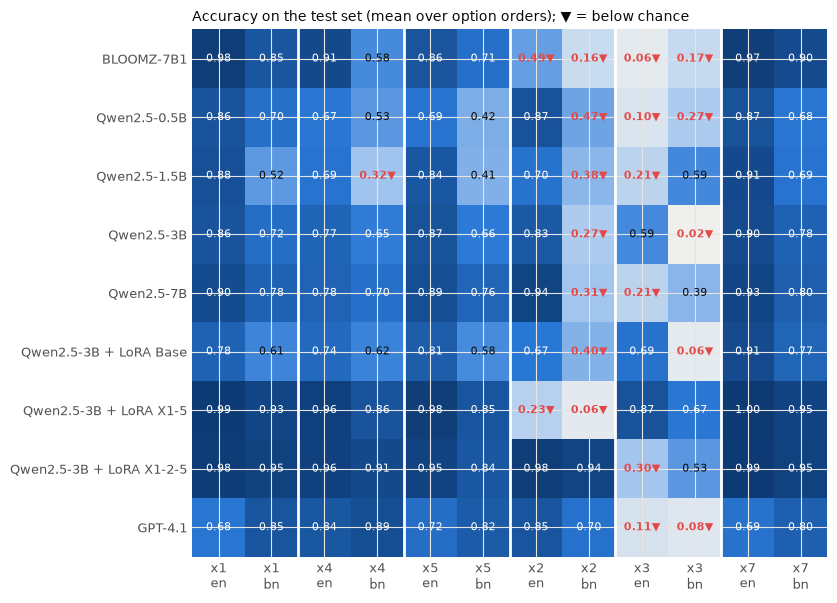

In [48]:
# B1. fingerprint: every model x core condition
fig, ax = plt.subplots(figsize=(1.0 + 0.62 * len(core), 0.5 * len(MODELS) + 1.6))
vals = ACC[core].to_numpy(float)
ax.imshow(vals, cmap=SEQ, vmin=0, vmax=1, aspect="auto")
for i in range(len(MODELS)):
    for j, c in enumerate(core):
        v = vals[i, j]
        if np.isnan(v):
            ax.text(j, i, "–", ha="center", va="center", color=MUTED, fontsize=8); continue
        below = v < chance(c)
        ax.text(j, i, f"{v:.2f}" + ("▼" if below else ""), ha="center", va="center", fontsize=8,
                color=LOSS if below else ("white" if v > 0.62 else INK), fontweight="bold" if below else None)
ax.set_xticks(range(len(core)), [c.replace("_", "\n") for c in core])
ax.set_yticks(range(len(MODELS)), MODELS)
for j in range(2, len(core), 2):
    ax.axvline(j - 0.5, color="white", lw=2)
ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
ax.set_title("Accuracy on the test set (mean over option orders); ▼ = below chance", loc="left", fontsize=10, color=INK)
plt.tight_layout(); fig.savefig(FIG / "B1_fingerprint.png", dpi=200, bbox_inches="tight"); plt.show()

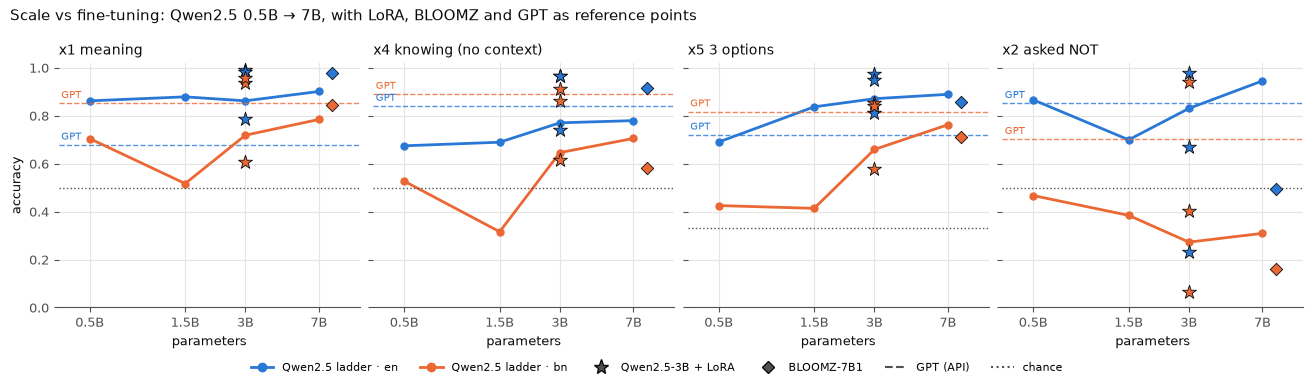

In [49]:
# B2. the Qwen ladder: does scale help? (+ LoRA, BLOOMZ, GPT for reference)
ladder = sorted([m for m in MODELS if X_RUNS[m][1] == "Qwen2.5" and X_RUNS[m][3] != "fine-tuned"],
                key=lambda m: X_RUNS[m][2])
others = [m for m in MODELS if m not in ladder]
tasks = [t for t in ["x1", "x4", "x5", "x2"] if f"{t}_en" in ACC]
fig, axes = plt.subplots(1, len(tasks), figsize=(3.3 * len(tasks), 3.6), sharey=True)
axes = np.atleast_1d(axes)
sizes = [X_RUNS[m][2] for m in ladder]
for ax, t in zip(axes, tasks):
    for lang in ("en", "bn"):
        ys = [a(m, f"{t}_{lang}") for m in ladder]
        ax.plot(sizes, ys, color=LANG[lang], lw=2, marker="o", ms=5, label=f"Qwen2.5 · {lang}")
        for m in others:
            v, kind, size = a(m, f"{t}_{lang}"), X_RUNS[m][3], X_RUNS[m][2]
            if np.isnan(v):
                continue
            if size is None:                                    # API model: dashed line across the panel
                ax.axhline(v, color=LANG[lang], ls="--", lw=1, alpha=0.8)
                ax.text(min(sizes) * 0.72, v + 0.012, m.split("-")[0], fontsize=7, color=LANG[lang], va="bottom")
            else:
                mk = "*" if kind == "fine-tuned" else "D"
                x = size * (1.15 if mk == "D" else 1.0)            # nudge BLOOMZ off the Qwen-7B point
                ax.scatter(x, v, marker=mk, s=110 if mk == "*" else 40, color=LANG[lang],
                           edgecolor=INK, lw=0.6, zorder=4)
    ax.axhline(chance(f"{t}_en"), color=MUTED, ls=":", lw=1)
    ax.set_xscale("log"); ax.set_xticks(sizes, [f"{s:g}B" for s in sizes]); ax.minorticks_off()
    ax.set_xlim(min(sizes) * 0.7, max(sizes) * 1.6)
    ax.set_title(TASK_NAME[t], fontsize=10, loc="left", color=INK); ax.set_xlabel("parameters")
axes[0].set_ylabel("accuracy"); axes[0].set_ylim(0, 1.02)
handles = [plt.Line2D([], [], color=LANG[l], marker="o", lw=2, label=f"Qwen2.5 ladder · {l}") for l in ("en", "bn")]
handles += [plt.Line2D([], [], color=MUTED, marker="*", ls="", ms=11, mec=INK, label="Qwen2.5-3B + LoRA"),
            plt.Line2D([], [], color=MUTED, marker="D", ls="", ms=6, mec=INK, label="BLOOMZ-7B1"),
            plt.Line2D([], [], color=MUTED, ls="--", label="GPT (API)"),
            plt.Line2D([], [], color=MUTED, ls=":", label="chance")]
fig.legend(handles=handles, loc="lower center", ncol=6, frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Scale vs fine-tuning: Qwen2.5 0.5B → 7B, with LoRA, BLOOMZ and GPT as reference points",
             x=0.01, ha="left", fontsize=10.5, color=INK)
plt.tight_layout(); fig.savefig(FIG / "B2_qwen_ladder.png", dpi=200, bbox_inches="tight"); plt.show()

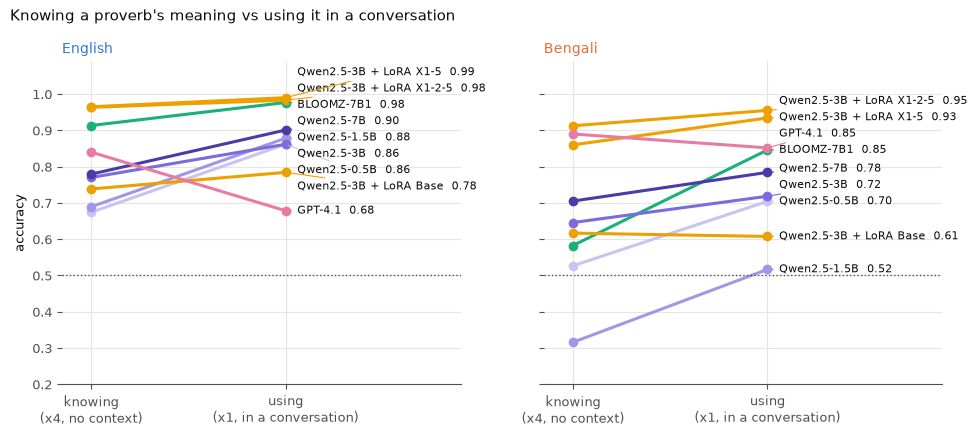

In [50]:
# B3. knowing (x4) vs using (x1), every model
if {"x4_en", "x1_en"} <= set(ACC):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True)
    for ax, lang in zip(axes, ["en", "bn"]):
        ends = []
        for m in MODELS:
            k, u = a(m, f"x4_{lang}"), a(m, f"x1_{lang}")
            if np.isnan(k) or np.isnan(u):
                continue
            ax.plot([0, 1], [k, u], color=model_color(m), lw=2.2, marker="o", ms=6)
            ends.append([u, m])
        ends.sort()
        ys, gap, top = [e[0] for e in ends], 0.045, 1.06
        for j in range(1, len(ys)):                         # spread labels so they do not overlap ...
            ys[j] = max(ys[j], ys[j - 1] + gap)
        if ys and ys[-1] > top:                             # ... and keep them inside the plot
            ys[-1] = top
            for j in range(len(ys) - 2, -1, -1):
                ys[j] = min(ys[j], ys[j + 1] - gap)
        for (u, m), y in zip(ends, ys):
            ax.annotate(f"{m}  {u:.2f}", (1, u), (1.06, y), va="center", fontsize=8, color=INK,
                        arrowprops=dict(arrowstyle="-", color=model_color(m), lw=0.8))
        ax.axhline(0.5, color=MUTED, ls=":", lw=1)
        ax.set_xticks([0, 1], ["knowing\n(x4, no context)", "using\n(x1, in a conversation)"])
        ax.set_xlim(-0.15, 1.9); ax.set_ylim(min(0.2, min(ys) - 0.05) if ys else 0.2, 1.09)
        ax.set_title({"en": "English", "bn": "Bengali"}[lang], fontsize=10, loc="left", color=LANG[lang])
    axes[0].set_ylabel("accuracy")
    fig.suptitle("Knowing a proverb's meaning vs using it in a conversation", x=0.01, ha="left", fontsize=10.5, color=INK)
    plt.tight_layout(); fig.savefig(FIG / "B3_knowing_vs_using.png", dpi=200, bbox_inches="tight"); plt.show()

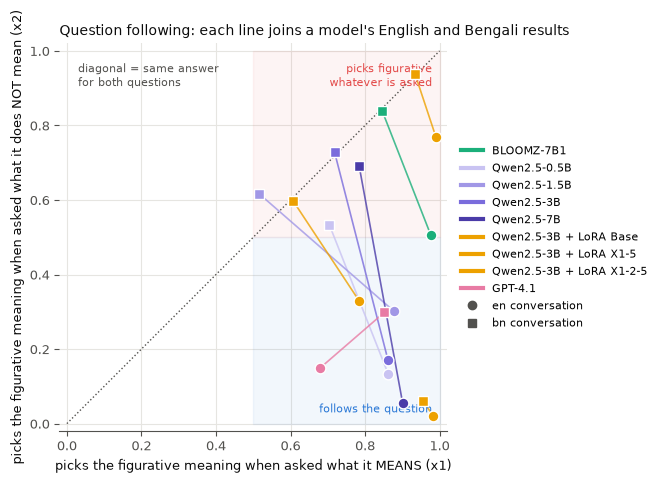

In [51]:
# B4. does the model follow the question? (x1 vs x2)
# x: share picking the figurative meaning when asked what the proverb MEANS (x1, should be high)
# y: share picking it when asked what it does NOT mean (x2, should be low)
FR = S.pivot(index="model", columns="label", values="fig_rate").reindex(MODELS)
if {"x1_en", "x2_en"} <= set(FR):
    fig, ax = plt.subplots(figsize=(6.2, 5.6))
    ax.fill_between([0.5, 1], 0, 0.5, color=GAIN, alpha=0.06)
    ax.fill_between([0.5, 1], 0.5, 1, color=LOSS, alpha=0.06)
    ax.plot([0, 1], [0, 1], color=MUTED, ls=":", lw=1)
    ax.text(0.98, 0.03, "follows the question", ha="right", fontsize=8, color=GAIN)
    ax.text(0.98, 0.97, "picks figurative\nwhatever is asked", ha="right", va="top", fontsize=8, color=LOSS)
    ax.text(0.03, 0.97, "diagonal = same answer\nfor both questions", va="top", fontsize=8, color=MUTED)
    for m in MODELS:
        pts = [(FR.loc[m, f"x1_{l}"], FR.loc[m, f"x2_{l}"]) if f"x1_{l}" in FR else (np.nan, np.nan) for l in ("en", "bn")]
        if all(np.isnan(p).any() for p in pts):
            continue
        ax.plot([p[0] for p in pts], [p[1] for p in pts], color=model_color(m), lw=1.2, alpha=0.8)
        for (x, y), l, mk in zip(pts, ("en", "bn"), ("o", "s")):
            ax.scatter(x, y, marker=mk, s=60, color=model_color(m), edgecolor="white", lw=1, zorder=3)
    hm = [plt.Line2D([], [], color=model_color(m), lw=3, label=m) for m in MODELS]
    hl = [plt.Line2D([], [], color=MUTED, marker=mk, ls="", label=f"{l} conversation") for l, mk in (("en", "o"), ("bn", "s"))]
    ax.legend(handles=hm + hl, frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
    ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02); ax.set_aspect("equal")
    ax.set_xlabel("picks the figurative meaning when asked what it MEANS (x1)")
    ax.set_ylabel("picks the figurative meaning when asked what it does NOT mean (x2)")
    ax.set_title("Question following: each line joins a model's English and Bengali results", loc="left", fontsize=10, color=INK)
    plt.tight_layout(); fig.savefig(FIG / "B4_question_following.png", dpi=200, bbox_inches="tight"); plt.show()

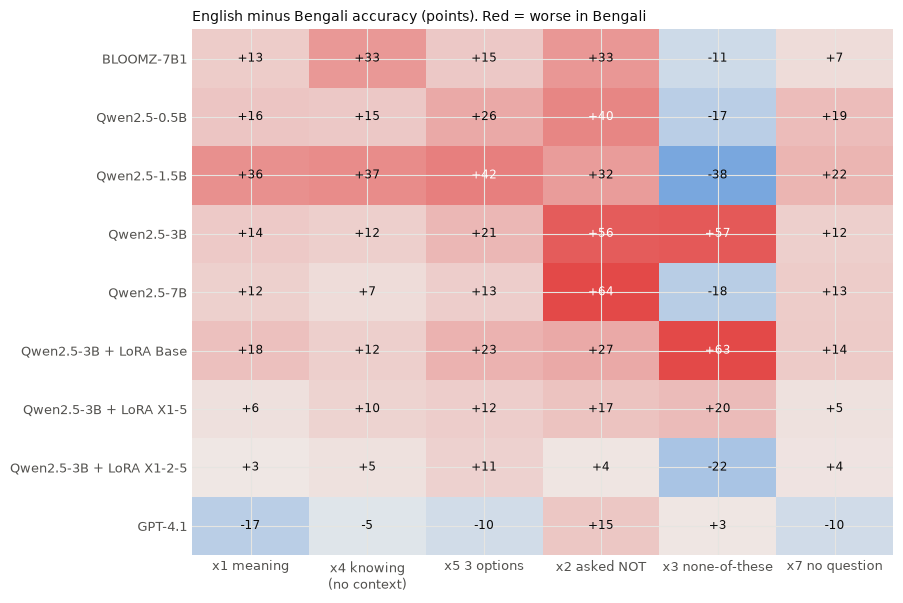

In [52]:
# B5. the Bengali gap (English − Bengali accuracy), every model and task
gap_tasks = [t for t in ["x1", "x4", "x5", "x2", "x3", "x7"] if f"{t}_en" in ACC and f"{t}_bn" in ACC]
GAP = pd.DataFrame({TASK_NAME[t]: (ACC[f"{t}_en"] - ACC[f"{t}_bn"]) * 100 for t in gap_tasks}).reindex(MODELS)
GAP.to_csv(TAB / "x_bengali_gap_points.csv")
fig, ax = plt.subplots(figsize=(1.6 + 1.25 * len(gap_tasks), 0.5 * len(MODELS) + 1.6))
lim = np.nanmax(np.abs(GAP.to_numpy())) or 1
ax.imshow(-GAP.to_numpy(float), cmap=DIV, norm=TwoSlopeNorm(0, -lim, lim), aspect="auto")
for i in range(len(MODELS)):
    for j in range(len(gap_tasks)):
        v = GAP.iat[i, j]
        ax.text(j, i, "–" if np.isnan(v) else f"{v:+.0f}", ha="center", va="center", fontsize=8.5,
                color=INK if np.isnan(v) or abs(v) < 0.6 * lim else "white")
ax.set_xticks(range(len(gap_tasks)), [c.replace(" (", "\n(") for c in GAP.columns]); ax.set_yticks(range(len(MODELS)), MODELS)
ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
ax.set_title("English minus Bengali accuracy (points). Red = worse in Bengali", loc="left", fontsize=10, color=INK)
plt.tight_layout(); fig.savefig(FIG / "B5_bengali_gap.png", dpi=200, bbox_inches="tight"); plt.show()

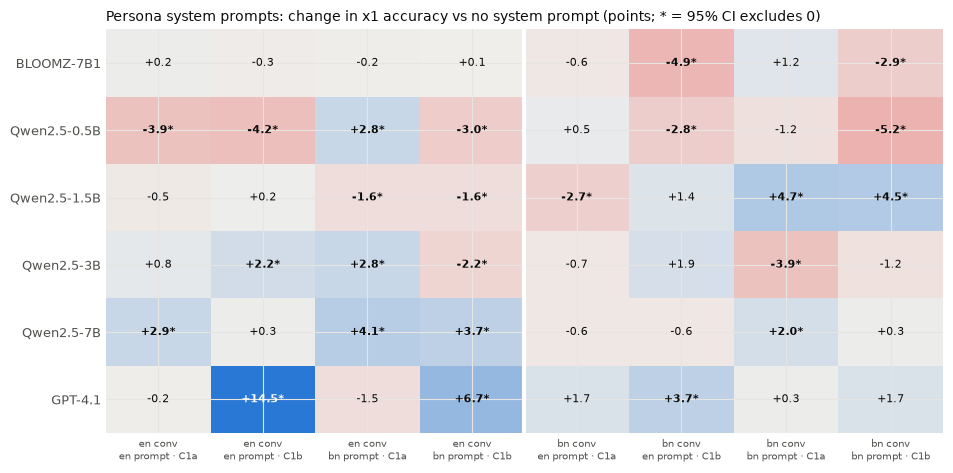

In [53]:
# B6. persona system prompts (x8): change vs no system prompt, every model
def paired_diff(model, base_label, label):
    m = IT[(IT.model_name == model) & (IT.label == base_label)].set_index("item_id")[["acc", "proverb_id"]].join(
        IT[(IT.model_name == model) & (IT.label == label)].set_index("item_id")["acc"].rename("b"), how="inner")
    if m.empty:
        return np.nan, np.nan, np.nan
    d = m["b"] - m["acc"]
    lo, hi = boot_ci(d, m["proverb_id"])
    return d.mean() * 100, lo * 100, hi * 100

PERSONA_COLS = [(conv, pl, c) for conv in ("en", "bn") for pl in ("en", "bn") for c in ("C1a", "C1b")]
prow = []
for m in MODELS:
    for conv, pl, c in PERSONA_COLS:
        lab = f"x8_{conv}_{c}" if pl == "en" else f"x8_{conv}_pbn_{c}"
        d, lo, hi = paired_diff(m, f"x8_{conv}_C0", lab)
        prow.append({"model": m, "conv": conv, "prompt_lang": pl, "cond": c, "diff_pts": d, "ci_lo": lo, "ci_hi": hi})
P8 = pd.DataFrame(prow)
P8.to_csv(TAB / "x8_persona_effects.csv", index=False)
P8m = P8.dropna(subset=["diff_pts"])
if not P8m.empty:
    pm = [m for m in MODELS if m in set(P8m.model)]
    cols = [f"{conv} conv\n{pl} prompt · {c}" for conv, pl, c in PERSONA_COLS]
    V = np.array([[P8.query("model == @m and conv == @cv and prompt_lang == @pl and cond == @c").diff_pts.iat[0]
                   for cv, pl, c in PERSONA_COLS] for m in pm])
    SIG = np.array([[(lambda r: r.ci_lo.iat[0] > 0 or r.ci_hi.iat[0] < 0)(
        P8.query("model == @m and conv == @cv and prompt_lang == @pl and cond == @c")) for cv, pl, c in PERSONA_COLS] for m in pm])
    lim = np.nanmax(np.abs(V)) or 1
    fig, ax = plt.subplots(figsize=(1.6 + 1.0 * len(cols), 0.5 * len(pm) + 1.8))
    ax.imshow(V, cmap=DIV, norm=TwoSlopeNorm(0, -lim, lim), aspect="auto")
    for i in range(len(pm)):
        for j in range(len(cols)):
            v = V[i, j]
            ax.text(j, i, "–" if np.isnan(v) else f"{v:+.1f}" + ("*" if SIG[i, j] else ""), ha="center", va="center",
                    fontsize=8, color=INK if np.isnan(v) or abs(v) < 0.6 * lim else "white",
                    fontweight="bold" if SIG[i, j] else None)
    ax.axvline(3.5, color="white", lw=3)
    ax.set_xticks(range(len(cols)), cols, fontsize=7.5); ax.set_yticks(range(len(pm)), pm)
    ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
    ax.set_title("Persona system prompts: change in x1 accuracy vs no system prompt (points; * = 95% CI excludes 0)",
                 loc="left", fontsize=10, color=INK)
    plt.tight_layout(); fig.savefig(FIG / "B6_persona_effects.png", dpi=200, bbox_inches="tight"); plt.show()
else:
    print("no x8 results found")

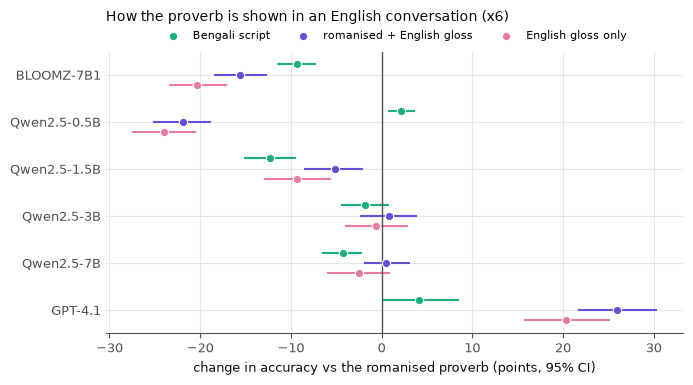

In [54]:
# B7. how the proverb is shown (x6): change vs the romanised proverb
R6 = [r for r in ("bengali", "gloss", "gloss_only") if any(IT.label == f"x6_{r}")]
if R6 and any(IT.label == "x6_romanised"):
    r6 = []
    for m in MODELS:
        for r in R6:
            d, lo, hi = paired_diff(m, "x6_romanised", f"x6_{r}")
            r6.append({"model": m, "render": r, "diff_pts": d, "ci_lo": lo, "ci_hi": hi})
    R6T = pd.DataFrame(r6); R6T.to_csv(TAB / "x6_render_effects.csv", index=False)
    pm = [m for m in MODELS if R6T.query("model == @m").diff_pts.notna().any()]
    fig, ax = plt.subplots(figsize=(7, 0.42 * len(pm) + 1.4))
    off = {r: (k - (len(R6) - 1) / 2) * 0.22 for k, r in enumerate(R6)}
    rcol = {"bengali": "#1baf7a", "gloss": "#6250d6", "gloss_only": "#e87ba4"}
    for i, m in enumerate(pm):
        for r in R6:
            row = R6T.query("model == @m and render == @r")
            if row.diff_pts.isna().all():
                continue
            ax.hlines(i + off[r], row.ci_lo.iat[0], row.ci_hi.iat[0], color=rcol[r], lw=1.5)
            ax.scatter(row.diff_pts.iat[0], i + off[r], color=rcol[r], s=36, zorder=3, edgecolor="white", lw=0.8,
                       label={"bengali": "Bengali script", "gloss": "romanised + English gloss",
                              "gloss_only": "English gloss only"}[r] if i == 0 else None)
    ax.axvline(0, color=MUTED, lw=1)
    ax.set_yticks(range(len(pm)), pm); ax.invert_yaxis(); ax.tick_params(axis="y", length=0)
    ax.set_xlabel("change in accuracy vs the romanised proverb (points, 95% CI)")
    ax.legend(frameon=False, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3)
    ax.set_title("How the proverb is shown in an English conversation (x6)", loc="left", fontsize=10, color=INK, pad=22)
    plt.tight_layout(); fig.savefig(FIG / "B7_render_effects.png", dpi=200, bbox_inches="tight"); plt.show()

In [55]:
# B8. LoRA vs scale: 3B + LoRA against 3B and 7B
ft, base = LORA
big = max(ladder, key=lambda m: X_RUNS[m][2]) if ladder else None
if ft in MODELS and base in MODELS:
    labs = [c for c in core if not np.isnan(a(ft, c)) and not np.isnan(a(base, c))]
    lrow = []
    for c in labs:
        mb = IT[(IT.model_name == base) & (IT.label == c)].set_index("item_id")[["acc", "proverb_id"]]
        mf = IT[(IT.model_name == ft) & (IT.label == c)].set_index("item_id")["acc"].rename("ft")
        j = mb.join(mf, how="inner"); dd = j["ft"] - j["acc"]; lo, hi = boot_ci(dd, j["proverb_id"])
        lrow.append({"label": c, "trained": c.split("_")[0] in ("x1", "x5"), "base": a(base, c), "lora": a(ft, c),
                     "big": a(big, c) if big else np.nan, "diff_pts": dd.mean() * 100, "ci_lo": lo * 100, "ci_hi": hi * 100})
    LT = pd.DataFrame(lrow).sort_values("trained", ascending=False, kind="stable").reset_index(drop=True)
    LT.to_csv(TAB / "lora_vs_base_vs_7b.csv", index=False); display(LT.round(3))
    fig, ax = plt.subplots(figsize=(7.5, 0.42 * len(LT) + 1.5))
    for i, r in LT.iterrows():
        col = GAIN if r.lora >= r.base else LOSS
        ax.annotate("", xy=(r.lora, i), xytext=(r.base, i),
                    arrowprops=dict(arrowstyle="-|>", color=col, lw=2, shrinkA=4, shrinkB=4, mutation_scale=10)) \
            if abs(r.lora - r.base) > 0.02 else ax.plot([r.base, r.lora], [i, i], color=col, lw=2)
        ax.scatter(r.base, i, s=45, facecolor="white", edgecolor=MUTED, lw=1.5, zorder=3)
        ax.scatter(r.lora, i, s=45, color=col, edgecolor="white", zorder=3)
        if not np.isnan(r.big):
            ax.scatter(r.big, i, marker="|", s=200, color=INK, lw=2, zorder=4)
        ax.text(1.02, i, f"{r.diff_pts:+.1f} [{r.ci_lo:+.1f}, {r.ci_hi:+.1f}]", va="center", fontsize=7.5, color=INK,
                transform=ax.get_yaxis_transform())
    ntr = int(LT.trained.sum())
    ax.axhspan(-0.5, ntr - 0.5, color=GAIN, alpha=0.05)
    ax.set_yticks(range(len(LT)), [l + ("  (trained)" if t else "") for l, t in zip(LT.label, LT.trained)])
    ax.invert_yaxis(); ax.tick_params(axis="y", length=0); ax.set_xlim(0, 1)
    ax.set_xlabel("accuracy")
    ax.legend(handles=[plt.Line2D([], [], marker="o", mfc="white", mec=MUTED, ls="", label=base),
                       plt.Line2D([], [], marker="o", color=GAIN, ls="", label=ft),
                       plt.Line2D([], [], marker="|", color=INK, ls="", ms=12, mew=2, label=big or "")],
              frameon=False, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3)
    ax.set_title("Does fine-tuning a 3B model beat scaling to 7B?", loc="left", fontsize=10, color=INK, pad=22)
    plt.tight_layout(); fig.savefig(FIG / "B8_lora_vs_scale.png", dpi=200, bbox_inches="tight"); plt.show()

,consistent,acc,acc_seed0,orders
model,,,,
BLOOMZ-7B1,0.787,0.638,0.637,3
Qwen2.5-0.5B,0.548,0.594,0.596,3
Qwen2.5-1.5B,0.755,0.594,0.586,3
Qwen2.5-3B,0.784,0.660,0.658,3
Qwen2.5-7B,0.753,0.701,0.701,3
Qwen2.5-3B + LoRA Base,0.703,0.637,0.631,3
Qwen2.5-3B + LoRA X1-5,0.928,0.780,0.776,3
Qwen2.5-3B + LoRA X1-2-5,0.907,0.858,0.856,3
GPT-4.1,NaN,0.670,0.670,1


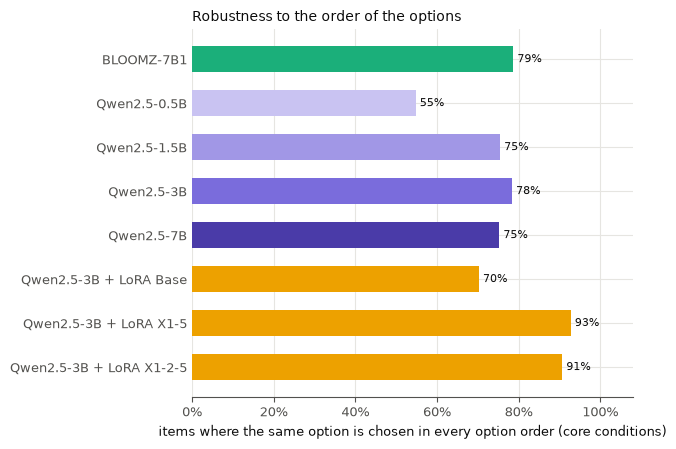

In [56]:
# B9. robustness to option order
rob = S[S.label.isin(core)].groupby("model", observed=True).agg(
    consistent=("consistent", "mean"), acc=("acc", "mean"), acc_seed0=("acc_seed0", "mean"),
    orders=("orders", "max")).reindex(MODELS)
rob.to_csv(TAB / "x_order_robustness.csv"); display(rob.round(3))
rb = rob.dropna(subset=["consistent"])
if not rb.empty:
    fig, ax = plt.subplots(figsize=(6.5, 0.42 * len(rb) + 1.2))
    ax.barh(range(len(rb)), rb.consistent, color=[model_color(m) for m in rb.index], height=0.6)
    for i, v in enumerate(rb.consistent):
        ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=8, color=INK)
    ax.set_yticks(range(len(rb)), rb.index); ax.invert_yaxis(); ax.tick_params(axis="y", length=0)
    ax.set_xlim(0, 1.08); ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_xlabel("items where the same option is chosen in every option order (core conditions)")
    ax.set_title("Robustness to the order of the options", loc="left", fontsize=10, color=INK)
    plt.tight_layout(); fig.savefig(FIG / "B9_order_robustness.png", dpi=200, bbox_inches="tight"); plt.show()

In [57]:
# B10. key numbers
lines = ["| model | x4 en / bn (knowing) | x1 en / bn (using) | x2 en / bn (asked NOT) | x5 en / bn | consistent |",
         "|---|---|---|---|---|---|"]
f = lambda m, t: " / ".join("–" if np.isnan(a(m, f"{t}_{l}")) else f"{a(m, f'{t}_{l}'):.2f}" for l in ("en", "bn"))
for m in MODELS:
    c = rob.loc[m, "consistent"] if m in rob.index else np.nan
    lines.append(f"| {m} | {f(m, 'x4')} | {f(m, 'x1')} | {f(m, 'x2')} | {f(m, 'x5')} | "
                 f"{'–' if np.isnan(c) else f'{c:.0%}'} |")
md = "\n".join(lines)
(TAB / "key_numbers_x.md").write_text(md, encoding="utf-8")
display(Markdown(md))

| model | x4 en / bn (knowing) | x1 en / bn (using) | x2 en / bn (asked NOT) | x5 en / bn | consistent |
|---|---|---|---|---|---|
| BLOOMZ-7B1 | 0.91 / 0.58 | 0.98 / 0.85 | 0.49 / 0.16 | 0.86 / 0.71 | 79% |
| Qwen2.5-0.5B | 0.67 / 0.53 | 0.86 / 0.70 | 0.87 / 0.47 | 0.69 / 0.42 | 55% |
| Qwen2.5-1.5B | 0.69 / 0.32 | 0.88 / 0.52 | 0.70 / 0.38 | 0.84 / 0.41 | 75% |
| Qwen2.5-3B | 0.77 / 0.65 | 0.86 / 0.72 | 0.83 / 0.27 | 0.87 / 0.66 | 78% |
| Qwen2.5-7B | 0.78 / 0.70 | 0.90 / 0.78 | 0.94 / 0.31 | 0.89 / 0.76 | 75% |
| Qwen2.5-3B + LoRA Base | 0.74 / 0.62 | 0.78 / 0.61 | 0.67 / 0.40 | 0.81 / 0.58 | 70% |
| Qwen2.5-3B + LoRA X1-5 | 0.96 / 0.86 | 0.99 / 0.93 | 0.23 / 0.06 | 0.98 / 0.85 | 93% |
| Qwen2.5-3B + LoRA X1-2-5 | 0.96 / 0.91 | 0.98 / 0.95 | 0.98 / 0.94 | 0.95 / 0.84 | 91% |
| GPT-4.1 | 0.84 / 0.89 | 0.68 / 0.85 | 0.85 / 0.70 | 0.72 / 0.82 | – |

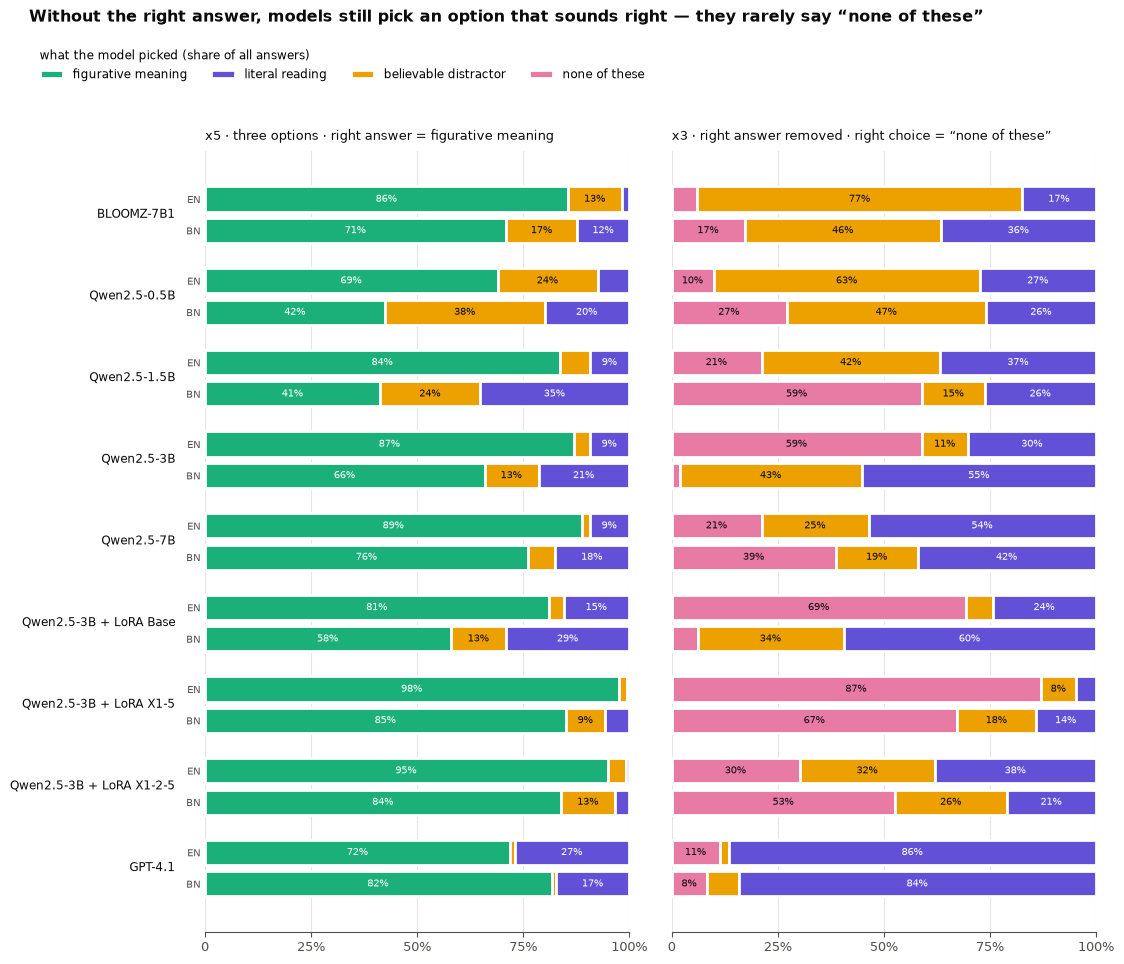

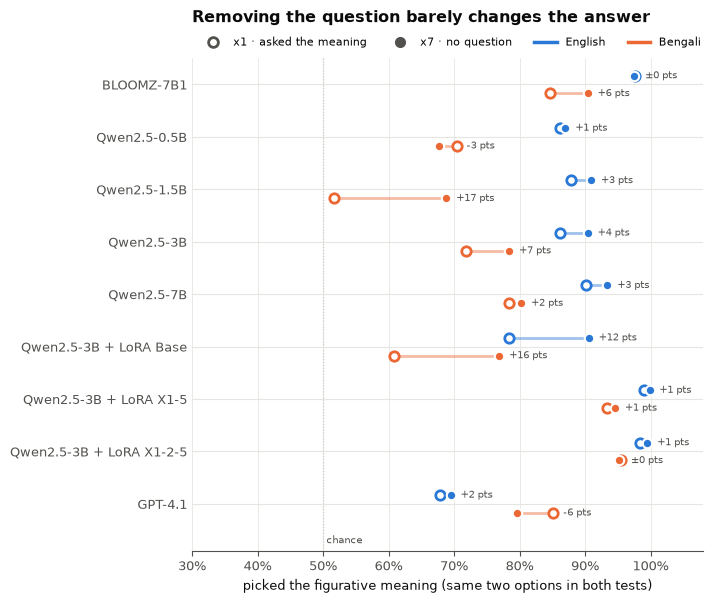

In [58]:
# ================================================================ B11. defaults: no question (x7) and no right answer (x3)
KEYCOL = {"correct": "#1baf7a", "literal": "#6250d6", "plausible": "#eda100", "none": "#e87ba4"}
KEYNAME = {"correct": "figurative meaning", "literal": "literal reading",
           "plausible": "believable distractor", "none": "none of these"}
KEYTEXT = {"correct": "white", "literal": "white", "plausible": INK, "none": INK}   # label colour inside each segment

def pick_shares(label):
    """share of answers (all option orders) that picked each option kind, per model and language"""
    rows = []
    for m in MODELS:
        for lang in ("en", "bn"):
            s = X[(X["model_name"] == m) & (X["label"] == f"{label}_{lang}")]["pred_key"].dropna()
            r = s.value_counts(normalize=True).to_dict() if len(s) else {}
            rows.append({"model": m, "lang": lang, **r})
    return pd.DataFrame(rows).fillna(0)

def stacked_picks(ax, P, keys, title):
    y = np.arange(len(P))[::-1] + np.repeat(np.arange(len(MODELS))[::-1], 2) * 0.6   # gap between models
    left = np.zeros(len(P))
    for k in keys:
        w = P[k].values if k in P else np.zeros(len(P))
        ax.barh(y, w, left=left, height=0.8, color=KEYCOL[k], edgecolor="white", lw=2, label=KEYNAME[k])
        for yi, l, wi in zip(y, left, w):
            if wi >= 0.08:
                ax.text(l + wi / 2, yi, f"{wi:.0%}", ha="center", va="center", fontsize=7.5, color=KEYTEXT[k])
        left += w
    ax.set_yticks(y, P["lang"].str.upper())
    ax.tick_params(axis="y", length=0, labelsize=7.5)
    ax.set_xlim(0, 1); ax.set_xticks([0, .25, .5, .75, 1], ["0", "25%", "50%", "75%", "100%"])
    ax.spines[["left"]].set_visible(False)
    ax.set_title(title, loc="left", fontsize=9.5, color=INK, pad=8)
    return y

P5, P3 = pick_shares("x5"), pick_shares("x3")
if (P5.drop(columns=["model", "lang"]).sum(axis=1) == 0).all() or (P3.drop(columns=["model", "lang"]).sum(axis=1) == 0).all():
    print("B11: no pred_key for x5 or x3 — skipped")
else:
    keys3 = ["none", "plausible", "literal"] + (["correct"] if "correct" in P3 else [])   # gold first, then the rest
    fig, axes = plt.subplots(1, 2, figsize=(11, 0.42 * len(P5) + 2.2), sharey=True)
    y = stacked_picks(axes[0], P5, ["correct", "plausible", "literal"], "x5 · three options · right answer = figurative meaning")
    stacked_picks(axes[1], P3, keys3, "x3 · right answer removed · right choice = “none of these”")
    for i, m in enumerate(MODELS):                                       # model name beside its EN/BN pair
        axes[0].text(-0.07, y[2 * i:2 * i + 2].mean(), m, transform=axes[0].get_yaxis_transform(),
                     ha="right", va="center", fontsize=8.5, color=INK)
    handles = {h.get_label(): h for ax in axes for h in ax.get_legend_handles_labels()[0]}
    fig.legend([handles[KEYNAME[k]] for k in KEYNAME if KEYNAME[k] in handles],
               [KEYNAME[k] for k in KEYNAME if KEYNAME[k] in handles],
               loc="upper left", bbox_to_anchor=(0.01, 0.965), ncol=4, frameon=False, fontsize=8.5,
               title="what the model picked (share of all answers)", title_fontsize=8.5, alignment="left")
    fig.suptitle("Without the right answer, models still pick an option that sounds right — they rarely say “none of these”",
                 x=0.01, y=0.995, va="top", ha="left", fontsize=11.5, color=INK, fontweight="bold")
    fig.subplots_adjust(left=0.17, right=0.98, top=0.85, bottom=0.05, wspace=0.1)
    fig.savefig(FIG / "B11_option_picks.png", dpi=200, bbox_inches="tight"); plt.show()
    pd.concat([P5.assign(test="x5"), P3.assign(test="x3")]).to_csv(TAB / "x_option_picks.csv", index=False)

# x1 vs x7: same options, with and without the question (dumbbell; open = asked the meaning, filled = no question)
if not {"x1_en", "x7_en"} <= set(ACC.columns):
    print("B11b: x1 or x7 missing — skipped")
else:
    fig, ax = plt.subplots(figsize=(7.2, 0.5 * len(MODELS) + 1.6))
    for i, m in enumerate(MODELS):
        for lang in ("en", "bn"):
            yi = len(MODELS) - 1 - i + (0.17 if lang == "en" else -0.17)
            x1, x7 = a(m, f"x1_{lang}"), a(m, f"x7_{lang}")
            if np.isnan(x1) or np.isnan(x7):
                continue
            ax.plot([x1, x7], [yi, yi], color=LANG[lang], lw=2, alpha=0.45, zorder=1)
            ax.scatter(x1, yi, s=46, facecolor="white", edgecolor=LANG[lang], lw=2, zorder=3)
            ax.scatter(x7, yi, s=46, color=LANG[lang], edgecolor="white", lw=1.5, zorder=3)
            ax.text(max(x1, x7) + 0.015, yi, f"{(x7 - x1) * 100:+.0f} pts".replace("+0 ", "±0 ").replace("-0 ", "±0 "),
                    va="center", fontsize=7.5, color=MUTED)
    ax.set_yticks(range(len(MODELS)), MODELS[::-1]); ax.tick_params(axis="y", length=0)
    ax.axvline(0.5, color=MUTED, lw=0.8, ls=":", zorder=0); ax.text(0.505, -0.75, "chance", fontsize=7.5, color=MUTED)
    lo = min(0.3, np.floor(np.nanmin(ACC[["x1_en", "x1_bn", "x7_en", "x7_bn"]].values) * 10) / 10)
    ax.set_xlim(lo, 1.08); ax.set_ylim(-0.9, len(MODELS) - 0.5)
    ticks = np.arange(lo, 1.001, 0.1); ax.set_xticks(ticks, [f"{t:.0%}" for t in ticks])
    ax.grid(axis="x", color=GRID, lw=0.6); ax.set_axisbelow(True); ax.spines[["left"]].set_visible(False)
    ax.set_xlabel("picked the figurative meaning (same two options in both tests)")
    from matplotlib.lines import Line2D
    ax.legend([Line2D([], [], marker="o", ls="", mfc="white", mec=MUTED, mew=2, ms=7),
               Line2D([], [], marker="o", ls="", color=MUTED, ms=7),
               Line2D([], [], color=LANG["en"], lw=2.5), Line2D([], [], color=LANG["bn"], lw=2.5)],
              ["x1 · asked the meaning", "x7 · no question", "English", "Bengali"],
              loc="lower left", bbox_to_anchor=(0, 1.0), ncol=4, frameon=False, fontsize=8)
    ax.set_title("Removing the question barely changes the answer", loc="left", fontsize=11.5,
                 color=INK, fontweight="bold", pad=26)
    plt.tight_layout(); fig.savefig(FIG / "B11b_no_question.png", dpi=200, bbox_inches="tight"); plt.show()

## Part A · MAPS-style experiments (E1–E9)
Reads every `e*.csv` in each model's seed-0 and swapped folders. The experiment comes from the file name (`e2_lit_results_df.csv` → `e2_lit`), the condition from the `label` column when a file holds several, and `render` for E1.
**Check the inventory printed by the first cell**: if a file or condition looks wrong, send me that printout.

In [14]:
# A0. load + inventory
def load_maps(model, variant, folder):
    d = locate(folder)
    out = []
    for p in sorted(d.rglob("*.csv")):
        m = re.match(r"(e\d+[a-z0-9_]*?)(?:_results.*)?$", p.stem.lower())
        if not m:
            continue
        df = pd.read_csv(p)
        if "correct" not in df:
            print(f"  skip {p.name}: no 'correct' column"); continue
        e = m.group(1)
        df["correct"] = to_bool(df["correct"])
        if "render" in df and e.startswith("e1"):
            df["cond"] = e + "_" + df["render"].astype(str)
        elif "label" in df and df["label"].nunique() > 1:
            df["cond"] = df["label"].astype(str)
        else:
            df["cond"] = e
        if "proverb_id" not in df and "item_id" in df:
            df["proverb_id"] = df["item_id"].str.rsplit("_", n=1).str[0]
        out.append(df.assign(model_name=model, variant=variant, exp=e, file=p.name))
    return pd.concat(out, ignore_index=True) if out else pd.DataFrame()

parts = []
for m, vs in MAPS_RUNS.items():
    for v, folder in vs.items():
        try:
            parts.append(load_maps(m, v, folder))
        except FileNotFoundError as ex:
            print("missing:", ex)
MP = pd.concat([p for p in parts if not p.empty], ignore_index=True) if parts else pd.DataFrame()
MAPS_MODELS = [m for m in MAPS_RUNS if not MP.empty and m in set(MP.model_name)]
if not MP.empty:
    inv = MP.groupby(["model_name", "variant", "file", "cond"]).agg(rows=("correct", "size"), acc=("correct", "mean"))
    inv.to_csv(TAB / "maps_inventory.csv"); display(inv.round(3))

  skip e3_acc_bengali_df.csv: no 'correct' column
  skip e3_acc_bengali_lit_df.csv: no 'correct' column
  skip e3_acc_english_df.csv: no 'correct' column
  skip e3_acc_english_lit_df.csv: no 'correct' column
  skip e3_knowing_vs_using.csv: no 'correct' column
  skip e3_quad_bengali_df.csv: no 'correct' column
  skip e3_quad_bengali_lit_df.csv: no 'correct' column
  skip e3_quad_english_df.csv: no 'correct' column
  skip e3_quad_english_lit_df.csv: no 'correct' column
  skip e4_figurative.csv: no 'correct' column
  skip e4_figurative_bengali_df.csv: no 'correct' column
  skip e4_figurative_bengali_lit_df.csv: no 'correct' column
  skip e4_figurative_english_df.csv: no 'correct' column
  skip e4_figurative_english_lit_df.csv: no 'correct' column
  skip e5_negation.csv: no 'correct' column
  skip e3_acc_bengali_df_swaped.csv: no 'correct' column
  skip e3_acc_bengali_lit_df_swaped.csv: no 'correct' column
  skip e3_acc_english_df_swaped.csv: no 'correct' column
  skip e3_acc_english_lit_d

rows    acc
model_name variant file                             cond                   
BLOOMZ-7B1 seed0   e1_results_df.csv                e1_bengali  1000  0.088
                                                    e1_english  1000  0.006
                   e2_lit_results_df.csv            e2_lit       600  0.647
                   e2_results_df.csv                e2           600  0.720
                   e3_results_bengali_df.csv        e3           600  0.720
...                                                              ...    ...
OLMo-2-1B  swap    e5_control_results_df_swaped.csv e5_control   600  0.510
                   e5_negated_results_df_swaped.csv e5_negated  3000  0.490
                   e6_results_df_swaped.csv         e6          1800  0.518
                   e7_results_df_swaped.csv         e7           600  0.507
                   e9_results_df_swaped.csv         e9          1800  0.510

[66 rows x 2 columns]

,model_name,exp,cond,seed0,swap,mean,same_result_both_orders,matched
0,BLOOMZ-7B1,e1,e1_bengali,0.088,0.088,0.088,1.000,1000
1,BLOOMZ-7B1,e1,e1_english,0.006,0.006,0.006,1.000,1000
2,BLOOMZ-7B1,e2,e2,0.720,0.685,0.702,0.652,600
3,BLOOMZ-7B1,e2_lit,e2_lit,0.647,0.668,0.658,0.715,600
4,BLOOMZ-7B1,e3,e3,0.720,0.685,0.702,0.652,600
5,BLOOMZ-7B1,e5_control,e5_control,0.623,0.672,0.648,0.648,600
6,BLOOMZ-7B1,e5_negated,e5_negated,0.365,0.356,0.361,0.668,600
7,BLOOMZ-7B1,e6,e6,0.772,0.774,0.773,0.667,600
8,BLOOMZ-7B1,e7,e7,0.672,0.615,0.643,0.387,600
9,BLOOMZ-7B1,e9,e9,0.745,0.716,0.730,0.612,600


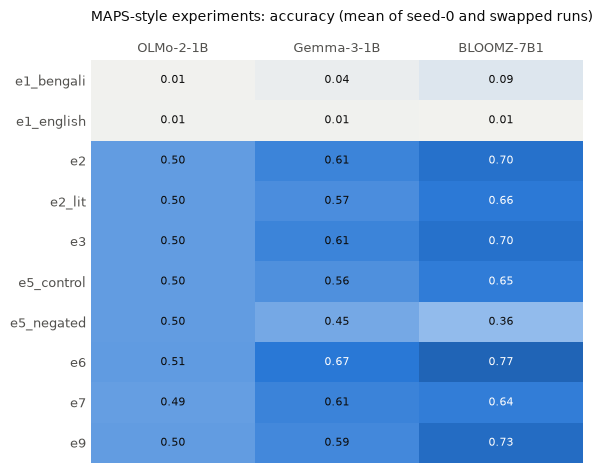

In [15]:
# A1. MAPS overview: seed 0, swapped, mean over the two orders
if not MP.empty:
    MS = MP.groupby(["model_name", "exp", "cond", "variant"])["correct"].mean().unstack("variant")
    if "swap" in MS and "seed0" in MS:
        MS["mean"] = MS[["seed0", "swap"]].mean(axis=1)
    else:
        MS["mean"] = MS.get("seed0", MS.iloc[:, 0])
    # consistency: same result in both orders, matching rows on the id columns both files have
    cons = []
    for (m, e, c), g in MP.groupby(["model_name", "exp", "cond"]):
        keys = [k for k in ("item_id", "proverb_id", "render", "template", "label") if k in g and g[k].notna().all()]
        if {"seed0", "swap"} <= set(g.variant) and keys:
            j = g[g.variant == "seed0"].drop_duplicates(keys).merge(g[g.variant == "swap"].drop_duplicates(keys),
                                                                    on=keys, suffixes=("_0", "_1"))
            cons.append({"model_name": m, "exp": e, "cond": c, "same_result_both_orders":
                         (j["correct_0"] == j["correct_1"]).mean() if len(j) else np.nan, "matched": len(j)})
    MS = MS.reset_index().merge(pd.DataFrame(cons), on=["model_name", "exp", "cond"], how="left") if cons else MS.reset_index()
    MS.to_csv(TAB / "maps_overview.csv", index=False); display(MS.round(3))

    H = MS.pivot_table(index="cond", columns="model_name", values="mean").reindex(columns=MAPS_MODELS)
    H = H.loc[sorted(H.index, key=lambda s: (int(re.match(r"e(\d+)", s.lower()).group(1)) if re.match(r"e\d+", s.lower()) else 99, s))]
    fig, ax = plt.subplots(figsize=(1.8 + 1.4 * len(MAPS_MODELS), 0.34 * len(H) + 1.4))
    ax.imshow(H.to_numpy(float), cmap=SEQ, vmin=0, vmax=1, aspect="auto")
    for i in range(H.shape[0]):
        for j in range(H.shape[1]):
            v = H.iat[i, j]
            ax.text(j, i, "–" if np.isnan(v) else f"{v:.2f}", ha="center", va="center", fontsize=8,
                    color=MUTED if np.isnan(v) else ("white" if v > 0.62 else INK))
    ax.set_xticks(range(len(MAPS_MODELS)), MAPS_MODELS); ax.set_yticks(range(len(H)), H.index)
    ax.xaxis.tick_top(); ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
    ax.set_title("MAPS-style experiments: accuracy (mean of seed-0 and swapped runs)", loc="left", fontsize=10,
                 color=INK, pad=28)
    plt.tight_layout(); fig.savefig(FIG / "A1_maps_overview.png", dpi=200, bbox_inches="tight"); plt.show()

,knows & uses,"knows, doesn't use",uses without knowing,neither,memorised,proverbs
model,,,,,,
OLMo-2-1B,0.025,0.000,0.975,0.000,0.025,200
Gemma-3-1B,0.080,0.005,0.805,0.110,0.085,200
BLOOMZ-7B1,0.135,0.025,0.725,0.115,0.160,200


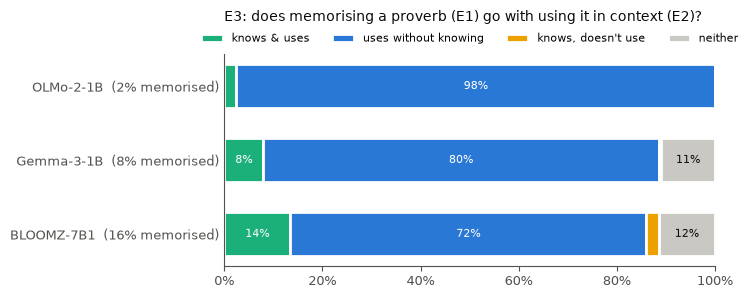

In [16]:
# A2. E3: memorised (E1) vs used in context (E2), per model
if not MP.empty and (MP.exp == "e1").any() and (MP.exp == "e2").any():
    q = []
    for m in MAPS_MODELS:
        e1 = MP[(MP.model_name == m) & (MP.exp == "e1")]
        e2 = MP[(MP.model_name == m) & (MP.exp == "e2")]
        if e1.empty or e2.empty:
            continue
        if "render" in e1 and (e1["render"] == "bengali").any():
            e1 = e1[e1["render"] == "bengali"]                         # memorised in Bengali script
        mem = e1.groupby("proverb_id")["correct"].any()                 # memorised: any of the templates completes it
        use = e2.groupby("proverb_id")["correct"].mean() >= 0.5         # uses: right on most items and both orders
        j = pd.concat([mem.rename("mem"), use.rename("use")], axis=1).dropna()
        j = j.astype(bool)
        q.append({"model": m, "knows & uses": (j.mem & j.use).mean(), "knows, doesn't use": (j.mem & ~j.use).mean(),
                  "uses without knowing": (~j.mem & j.use).mean(), "neither": (~j.mem & ~j.use).mean(),
                  "memorised": j.mem.mean(), "proverbs": len(j)})
    Q = pd.DataFrame(q).set_index("model"); Q.to_csv(TAB / "maps_e3_quadrants.csv"); display(Q.round(3))
    qcols = {"knows & uses": "#1baf7a", "uses without knowing": "#2a78d6", "knows, doesn't use": "#eda100",
             "neither": "#c9c8c2"}
    fig, ax = plt.subplots(figsize=(7.5, 0.55 * len(Q) + 1.4))
    left = np.zeros(len(Q))
    for k, col in qcols.items():
        ax.barh(range(len(Q)), Q[k], left=left, color=col, height=0.6, edgecolor="white", lw=2, label=k)
        for i, (l, w) in enumerate(zip(left, Q[k])):
            if w >= 0.06:
                ax.text(l + w / 2, i, f"{w:.0%}", ha="center", va="center", fontsize=8,
                        color="white" if k in ("knows & uses", "uses without knowing") else INK)
        left += Q[k].to_numpy()
    ax.set_yticks(range(len(Q)), [f"{m}  ({Q.loc[m, 'memorised']:.0%} memorised)" for m in Q.index]); ax.invert_yaxis()
    ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); ax.tick_params(axis="y", length=0)
    ax.legend(frameon=False, fontsize=8, ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0))
    ax.set_title("E3: does memorising a proverb (E1) go with using it in context (E2)?", loc="left", fontsize=10,
                 color=INK, pad=24)
    plt.tight_layout(); fig.savefig(FIG / "A2_maps_e3_memorised_vs_used.png", dpi=200, bbox_inches="tight"); plt.show()

figurative,False,True
model_name,,
OLMo-2-1B,0.500,0.500
Gemma-3-1B,0.611,0.613
BLOOMZ-7B1,0.828,0.680


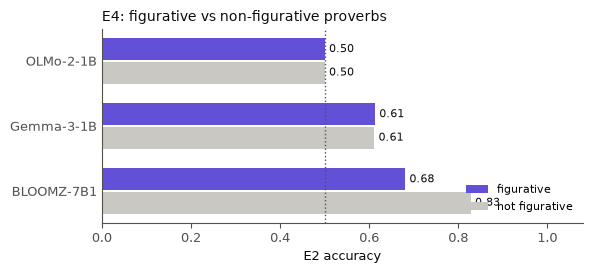

In [17]:
# A3. E4: figurative vs non-figurative proverbs (E2)
if not MP.empty and "figurative" in MP and (MP.exp == "e2").any():
    e2 = MP[MP.exp == "e2"].copy()
    e2["figurative"] = to_bool(e2["figurative"])
    F4 = e2.groupby(["model_name", "figurative"])["correct"].mean().unstack().reindex(MAPS_MODELS)
    F4.to_csv(TAB / "maps_e4_figurative.csv"); display(F4.round(3))
    fig, ax = plt.subplots(figsize=(6, 0.5 * len(F4) + 1.3))
    y = np.arange(len(F4))
    for k, (val, col, lab) in enumerate([(True, "#6250d6", "figurative"), (False, "#c9c8c2", "not figurative")]):
        if val in F4:
            ax.barh(y + (k - 0.5) * 0.36, F4[val], height=0.34, color=col, label=lab)
            for yi, v in zip(y, F4[val]):
                ax.text(v + 0.01, yi + (k - 0.5) * 0.36, f"{v:.2f}", va="center", fontsize=8, color=INK)
    ax.axvline(0.5, color=MUTED, ls=":", lw=1)
    ax.set_yticks(y, F4.index); ax.invert_yaxis(); ax.tick_params(axis="y", length=0); ax.set_xlim(0, 1.08)
    ax.set_xlabel("E2 accuracy"); ax.legend(frameon=False, fontsize=8, loc="lower right")
    ax.set_title("E4: figurative vs non-figurative proverbs", loc="left", fontsize=10, color=INK)
    plt.tight_layout(); fig.savefig(FIG / "A3_maps_e4_figurative.png", dpi=200, bbox_inches="tight"); plt.show()

In [18]:
# done: list what was written
print("figures:", *sorted(p.name for p in FIG.glob("*.png")), sep="\n  ")
print("tables:", *sorted(p.name for p in TAB.glob("*")), sep="\n  ")

figures:
  A1_maps_overview.png
  A2_maps_e3_memorised_vs_used.png
  A3_maps_e4_figurative.png
  B1_fingerprint.png
  B2_qwen_ladder.png
  B3_knowing_vs_using.png
  B4_question_following.png
  B5_bengali_gap.png
  B6_persona_effects.png
  B7_render_effects.png
  B8_lora_vs_scale.png
  B9_order_robustness.png
tables:
  key_numbers_x.md
  lora_vs_base_vs_7b.csv
  maps_e3_quadrants.csv
  maps_e4_figurative.csv
  maps_inventory.csv
  maps_overview.csv
  x6_render_effects.csv
  x8_persona_effects.csv
  x_accuracy_matrix.csv
  x_all_models_all_conditions.csv
  x_bengali_gap_points.csv
  x_order_robustness.csv
  x_scoring_check.csv


# Hero Figures

In [20]:
# H0. setup: read the cross-model tables
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D

TAB = OUT / "tables"
# TAB = Path("/kaggle/working/cross_model/tables")
HERO = TAB.parent / "hero"; HERO.mkdir(parents=True, exist_ok=True)

S = pd.read_csv(TAB / "x_all_models_all_conditions.csv")
LORA_T = pd.read_csv(TAB / "lora_vs_base_vs_7b.csv")
P8 = pd.read_csv(TAB / "x8_persona_effects.csv")
R6 = pd.read_csv(TAB / "x6_render_effects.csv")

ORDER = ["BLOOMZ-7B1", "Qwen2.5-0.5B", "Qwen2.5-1.5B", "Qwen2.5-3B", "Qwen2.5-7B",
         "Qwen2.5-3B + LoRA Base", "Qwen2.5-3B + LoRA", "GPT-4.1"]
SHORT = {"BLOOMZ-7B1": "BLOOMZ 7B", "Qwen2.5-0.5B": "Qwen 0.5B", "Qwen2.5-1.5B": "Qwen 1.5B", "Qwen2.5-3B": "Qwen 3B",
         "Qwen2.5-7B": "Qwen 7B", "Qwen2.5-3B + LoRA Base": "Qwen 3B (4-bit)", "Qwen2.5-3B + LoRA": "Qwen 3B + LoRA",
         "GPT-4.1": "GPT-4.1"}
LADDER = ["Qwen2.5-0.5B", "Qwen2.5-1.5B", "Qwen2.5-3B", "Qwen2.5-7B"]
SIZE = {"Qwen2.5-0.5B": 0.5, "Qwen2.5-1.5B": 1.5, "Qwen2.5-3B": 3, "Qwen2.5-7B": 7}
INK, MUTED, FAINT, GRID = "#0b0b0b", "#52514e", "#9c9a93", "#e6e5e1"
EN, BN, GAIN, LOSS = "#2a78d6", "#eb6834", "#2a78d6", "#e34948"
ORDER = [m for m in ORDER if m in set(S.model)]

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": FAINT, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 9.5, "xtick.labelsize": 9, "ytick.labelsize": 9.5,
    "legend.frameon": False, "legend.fontsize": 9})

def v(model, label, col="acc"):
    r = S[(S.model == model) & (S.label == label)]
    return r[col].iat[0] if len(r) else np.nan

def headline(fig, title, sub, y=1.0):
    fig.text(0.01, y + 0.06, title, fontsize=14, fontweight="bold", color=INK, ha="left", va="bottom")
    fig.text(0.01, y + 0.015, sub, fontsize=10, color=MUTED, ha="left", va="bottom")

def save(fig, name):
    fig.savefig(HERO / f"{name}.png", dpi=220, bbox_inches="tight")
    fig.savefig(HERO / f"{name}.pdf", bbox_inches="tight")        # vector copy for the paper
    plt.show()

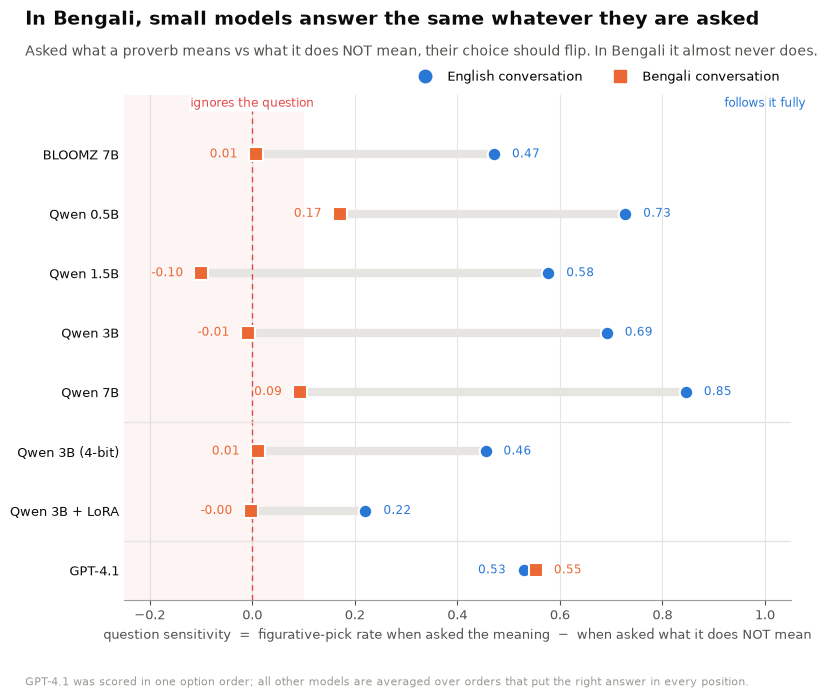

In [21]:
# H1. question sensitivity: does the answer change when the question flips?
# sensitivity = P(figurative | asked what it MEANS, x1) - P(figurative | asked what it does NOT mean, x2)
# 1 = answer flips with the question (reads it), 0 = same answer either way (ignores it)
QS = pd.DataFrame([{"model": m, **{l: v(m, f"x1_{l}", "fig_rate") - v(m, f"x2_{l}", "fig_rate") for l in ("en", "bn")}}
                   for m in ORDER]).dropna().set_index("model")
QS = QS.loc[[m for m in ORDER if m in QS.index]]
fig, ax = plt.subplots(figsize=(8.6, 0.62 * len(QS) + 1.6))
ax.axvspan(-0.25, 0.1, color=LOSS, alpha=0.06, lw=0)
ax.axvline(0, color=LOSS, lw=1, ls=(0, (4, 3)))
ax.text(0.0, -0.75, "ignores the question", color=LOSS, fontsize=8.5, ha="center", va="bottom",
        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))
ax.text(1.0, -0.75, "follows it fully", color=GAIN, fontsize=8.5, ha="center", va="bottom")
for i, (m, r) in enumerate(QS.iterrows()):
    ax.plot([r.bn, r.en], [i, i], color=GRID, lw=6, solid_capstyle="round", zorder=1)
    ax.scatter(r.en, i, s=95, color=EN, edgecolor="white", lw=1.5, zorder=3)
    ax.scatter(r.bn, i, s=95, marker="s", color=BN, edgecolor="white", lw=1.5, zorder=3)
    ax.text(r.en + (0.035 if r.en >= r.bn else -0.035), i, f"{r.en:.2f}", color=EN, fontsize=8.5, va="center",
            ha="left" if r.en >= r.bn else "right")
    ax.text(r.bn + (-0.035 if r.en >= r.bn else 0.035), i, f"{r.bn:.2f}", color=BN, fontsize=8.5, va="center",
            ha="right" if r.en >= r.bn else "left")
ax.set_yticks(range(len(QS)), [SHORT[m] for m in QS.index]); ax.invert_yaxis()
ax.tick_params(axis="y", length=0); ax.grid(axis="y", visible=False)
ax.set_xlim(-0.25, 1.05); ax.set_ylim(len(QS) - 0.5, -1.0)
ax.set_xlabel("question sensitivity  =  figurative-pick rate when asked the meaning  −  when asked what it does NOT mean")
ax.legend(handles=[Line2D([], [], marker="o", color=EN, ls="", ms=9, label="English conversation"),
                   Line2D([], [], marker="s", color=BN, ls="", ms=9, label="Bengali conversation")],
          loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2)
for i in range(1, len(QS)):                     # thin divider between model groups
    if ("LoRA" in QS.index[i]) != ("LoRA" in QS.index[i - 1]) or "GPT" in QS.index[i]:
        ax.axhline(i - 0.5, color=GRID, lw=1)
fig.text(0.01, -0.02, "GPT-4.1 was scored in one option order; all other models are averaged over orders that put the "
         "right answer in every position.", fontsize=8, color=FAINT)
headline(fig, "In Bengali, small models answer the same whatever they are asked",
         "Asked what a proverb means vs what it does NOT mean, their choice should flip. In Bengali it almost never does.",
         y=0.92)
save(fig, "H1_question_sensitivity")

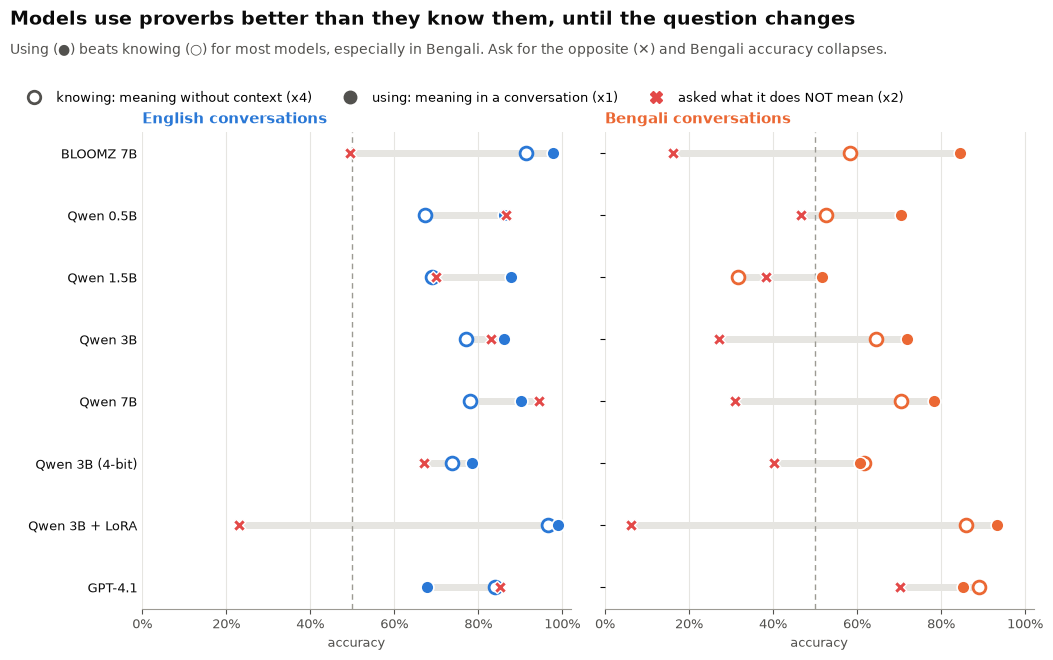

In [22]:
# ================================================================ H2. knowing, using, and the negation check: one row per model
fig, axes = plt.subplots(1, 2, figsize=(11.5, 0.55 * len(ORDER) + 1.8), sharey=True, gridspec_kw=dict(wspace=0.08))
for ax, lang, col in zip(axes, ("en", "bn"), (EN, BN)):
    ax.axvline(0.5, color=FAINT, lw=1, ls=(0, (4, 3)))
    for i, m in enumerate(ORDER):
        k, u, n = v(m, f"x4_{lang}"), v(m, f"x1_{lang}"), v(m, f"x2_{lang}")
        if np.isnan(u):
            continue
        lo, hi = np.nanmin([k, u, n]), np.nanmax([k, u, n])
        ax.plot([lo, hi], [i, i], color=GRID, lw=5, solid_capstyle="round", zorder=1)
        if not np.isnan(k):
            ax.scatter(k, i, s=85, facecolor="white", edgecolor=col, lw=2, zorder=3)
        ax.scatter(u, i, s=85, color=col, edgecolor="white", lw=1.2, zorder=4)
        if not np.isnan(n):
            ax.scatter(n, i, s=80, marker="X", color=LOSS, edgecolor="white", lw=1, zorder=4)
    ax.set_xlim(0, 1.02); ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.grid(axis="y", visible=False)
    ax.set_title({"en": "English conversations", "bn": "Bengali conversations"}[lang], loc="left", color=col,
                 fontweight="bold")
    ax.set_xlabel("accuracy")
axes[0].set_yticks(range(len(ORDER)), [SHORT[m] for m in ORDER]); axes[0].invert_yaxis()
axes[0].tick_params(axis="y", length=0)
fig.legend(handles=[Line2D([], [], marker="o", mfc="white", mec=MUTED, mew=2, ls="", ms=9, label="knowing: meaning without context (x4)"),
                    Line2D([], [], marker="o", color=MUTED, ls="", ms=9, label="using: meaning in a conversation (x1)"),
                    Line2D([], [], marker="X", color=LOSS, ls="", ms=9, label="asked what it does NOT mean (x2)")],
           loc="lower left", bbox_to_anchor=(0.01, 0.905), ncol=3)
headline(fig, "Models use proverbs better than they know them, until the question changes",
         "Using (●) beats knowing (○) for most models, especially in Bengali. Ask for the opposite (✕) and Bengali accuracy collapses.",
         y=0.985)
save(fig, "H2_knowing_using_negation")

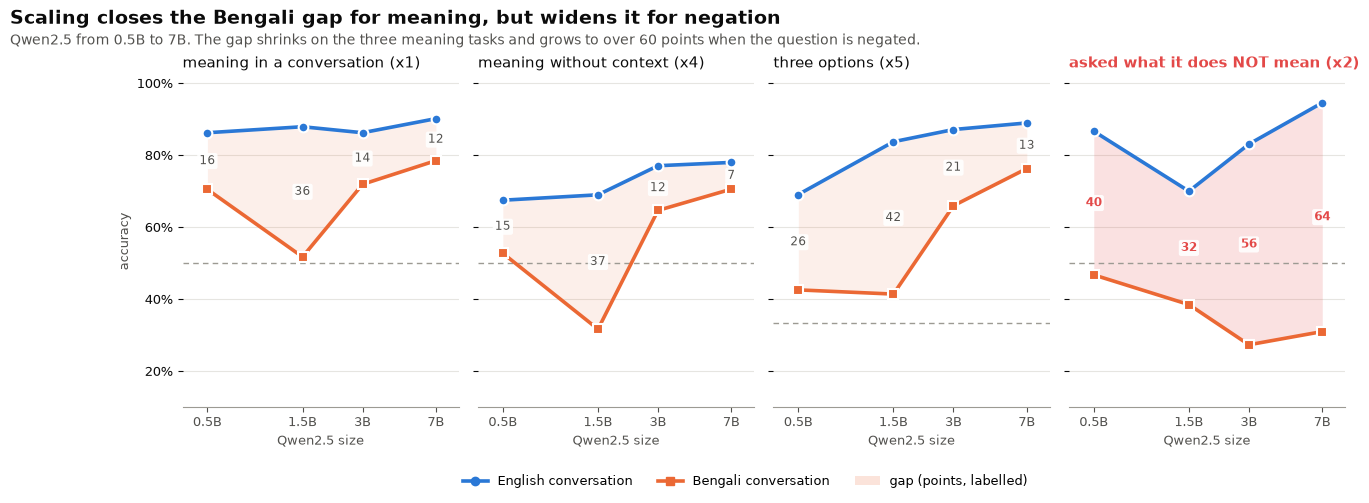

In [23]:
# ================================================================ H3. the Qwen ladder: the Bengali gap as a shaded band
tasks = [("x1", "meaning in a conversation (x1)"), ("x4", "meaning without context (x4)"),
         ("x5", "three options (x5)"), ("x2", "asked what it does NOT mean (x2)")]
lad = [m for m in LADDER if m in ORDER]
xs = np.array([SIZE[m] for m in lad])
fig, axes = plt.subplots(1, 4, figsize=(15, 4.3), sharey=True, gridspec_kw=dict(wspace=0.07))
for ax, (t, name) in zip(axes, tasks):
    en = np.array([v(m, f"{t}_en") for m in lad]); bn = np.array([v(m, f"{t}_bn") for m in lad])
    neg = t == "x2"
    ax.fill_between(xs, bn, en, color=LOSS if neg else BN, alpha=0.16 if neg else 0.10, lw=0)
    ax.plot(xs, en, color=EN, lw=2.6, marker="o", ms=7, mec="white", mew=1.5, zorder=3)
    ax.plot(xs, bn, color=BN, lw=2.6, marker="s", ms=7, mec="white", mew=1.5, zorder=3)
    for x, e, b in zip(xs, en, bn):
        ax.text(x, (e + b) / 2, f"{(e - b) * 100:.0f}", ha="center", va="center", fontsize=8.5,
                color=LOSS if neg else MUTED, fontweight="bold" if neg else None,
                bbox=dict(boxstyle="round,pad=0.18", fc="white", ec="none", alpha=0.9))
    ax.axhline(1 / 3 if t == "x5" else 0.5, color=FAINT, lw=1, ls=(0, (4, 3)))
    ax.set_xscale("log"); ax.set_xticks(xs, [f"{x:g}B" for x in xs]); ax.minorticks_off()
    ax.set_xlim(xs.min() * 0.75, xs.max() * 1.3); ax.set_ylim(0.1, 1.02)
    ax.grid(axis="x", visible=False)
    ax.set_title(name, loc="left", fontsize=10.5, color=LOSS if neg else INK, fontweight="bold" if neg else None)
    ax.set_xlabel("Qwen2.5 size")
axes[0].yaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); axes[0].set_ylabel("accuracy")
fig.legend(handles=[Line2D([], [], color=EN, marker="o", lw=2.6, label="English conversation"),
                    Line2D([], [], color=BN, marker="s", lw=2.6, label="Bengali conversation"),
                    plt.Rectangle((0, 0), 1, 1, fc=BN, alpha=0.18, label="gap (points, labelled)")],
           loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3)
headline(fig, "Scaling closes the Bengali gap for meaning, but widens it for negation",
         "Qwen2.5 from 0.5B to 7B. The gap shrinks on the three meaning tasks and grows to over 60 points when the question is negated.",
         y=0.93)
save(fig, "H3_qwen_ladder_gap")

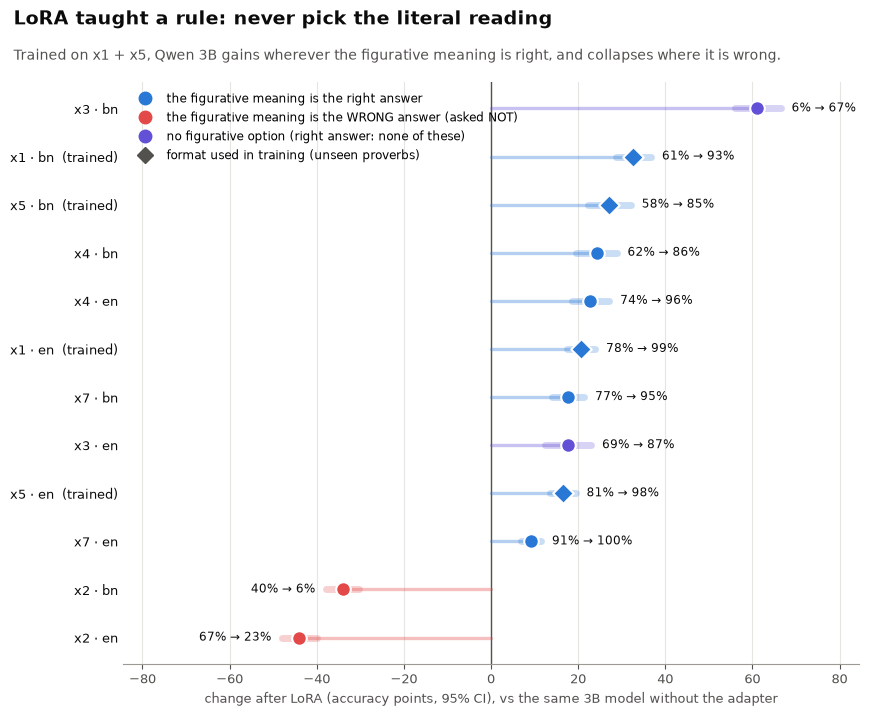

In [24]:
# ================================================================ H4. what LoRA fine-tuning actually learned
KIND = {"x1": "fig", "x4": "fig", "x5": "fig", "x7": "fig", "x2": "wrong", "x3": "absent"}
KCOL = {"fig": GAIN, "wrong": LOSS, "absent": "#6250d6"}
KNAME = {"fig": "the figurative meaning is the right answer",
         "wrong": "the figurative meaning is the WRONG answer (asked NOT)",
         "absent": "no figurative option (right answer: none of these)"}
L = LORA_T.copy()
L["kind"] = L["label"].str.split("_").str[0].map(KIND)
L["name"] = L["label"].str.replace("_", " · ") + np.where(L["trained"], "  (trained)", "")
L = L.sort_values("diff_pts").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9.5, 0.48 * len(L) + 1.8))
ax.axvline(0, color=MUTED, lw=1)
for i, r in L.iterrows():
    c = KCOL[r.kind]
    ax.plot([0, r.diff_pts], [i, i], color=c, lw=2.4, alpha=0.35, solid_capstyle="round")
    ax.plot([r.ci_lo, r.ci_hi], [i, i], color=c, lw=5, alpha=0.25, solid_capstyle="round")
    ax.scatter(r.diff_pts, i, s=110, color=c, edgecolor="white", lw=1.5, zorder=3,
               marker="D" if r.trained else "o")
    ax.text((r.ci_hi + 2.5) if r.diff_pts >= 0 else (r.ci_lo - 2.5), i,
            f"{r.base:.0%} → {r.lora:.0%}", va="center", ha="left" if r.diff_pts >= 0 else "right",
            fontsize=8.5, color=INK)
ax.set_yticks(range(len(L)), L["name"]); ax.tick_params(axis="y", length=0); ax.grid(axis="y", visible=False)
lim = max(abs(L.ci_lo.min()), abs(L.ci_hi.max())) + 18
ax.set_xlim(-lim, lim); ax.set_xlabel("change after LoRA (accuracy points, 95% CI), vs the same 3B model without the adapter")
ax.legend(handles=[Line2D([], [], marker="o", color=KCOL[k], ls="", ms=9, label=KNAME[k]) for k in KCOL] +
                  [Line2D([], [], marker="D", color=MUTED, ls="", ms=8, label="format used in training (unseen proverbs)")],
          loc="upper left", fontsize=8.5)
headline(fig, "LoRA taught a rule: never pick the literal reading",
         "Trained on x1 + x5, Qwen 3B gains wherever the figurative meaning is right, and collapses where it is wrong.",
         y=0.89)
save(fig, "H4_lora_learned_a_rule")

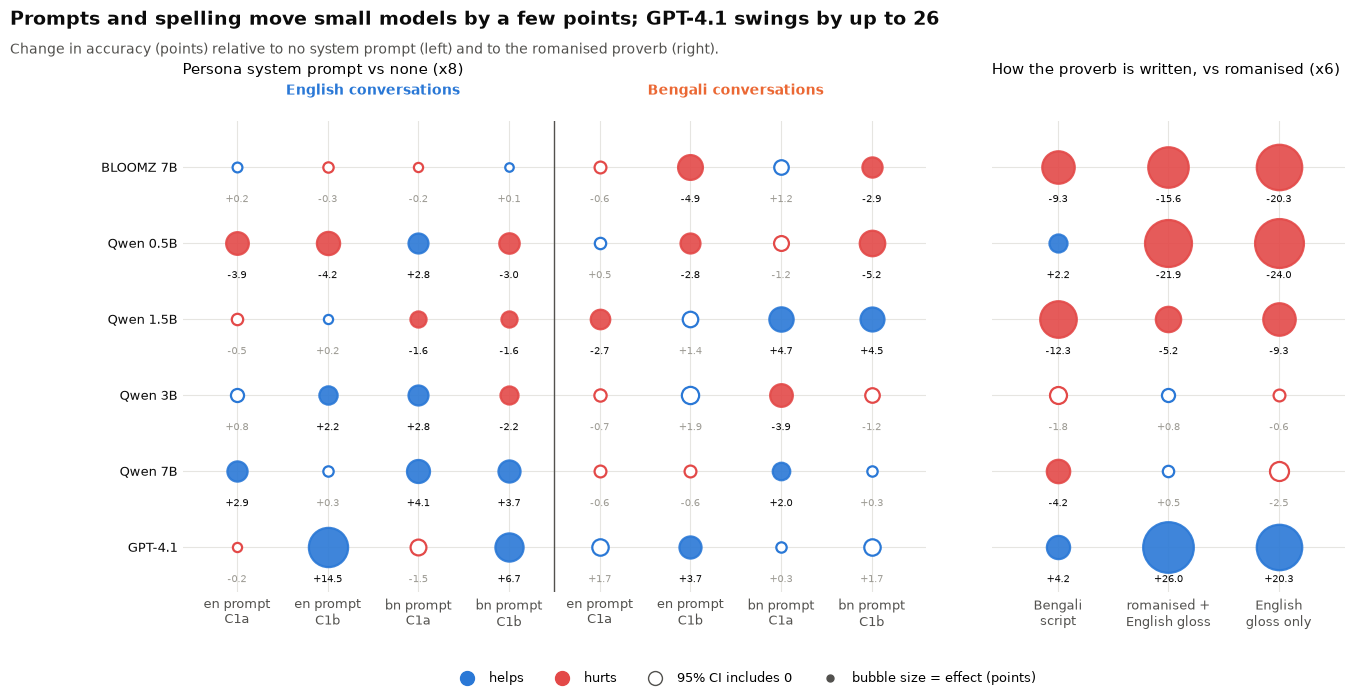

In [25]:
# ================================================================ H5. prompt and presentation effects as bubble matrices
def bubbles(ax, M, sig, cols, rows, scale):
    """M: rows x cols effects (points). Bubble area ~ |effect|, blue = helps, red = hurts, solid = 95% CI excludes 0."""
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            d = M[i, j]
            if np.isnan(d):
                ax.text(j, i, "–", ha="center", va="center", color=FAINT); continue
            c = GAIN if d > 0 else LOSS
            size = 30 + (abs(d) / scale) ** 0.9 * 1300
            ax.scatter(j, i, s=size, color=c if sig[i, j] else "white", edgecolor=c, lw=1.6,
                       alpha=0.9 if sig[i, j] else 1, zorder=3)
            ax.text(j, i + 0.36, f"{d:+.1f}", ha="center", va="top", fontsize=7.5,
                    color=INK if sig[i, j] else FAINT, zorder=4)
    ax.set_xticks(range(len(cols)), cols); ax.set_yticks(range(len(rows)), rows)
    ax.set_xlim(-0.6, len(cols) - 0.4); ax.set_ylim(len(rows) - 0.4, -0.6)
    ax.tick_params(length=0); ax.grid(color=GRID, lw=0.8)
    for sp in ax.spines.values():
        sp.set_visible(False)

pm = [m for m in ORDER if P8.query("model == @m").diff_pts.notna().any()]
pcols = [(c, pl, k) for c in ("en", "bn") for pl in ("en", "bn") for k in ("C1a", "C1b")]
get = lambda df, m, q: df.query(f"model == @m and {q}")
M8 = np.array([[get(P8, m, f"conv == '{c}' and prompt_lang == '{pl}' and cond == '{k}'").diff_pts.iat[0] for c, pl, k in pcols] for m in pm])
S8 = np.array([[(lambda r: (r.ci_lo.iat[0] > 0) or (r.ci_hi.iat[0] < 0))(get(P8, m, f"conv == '{c}' and prompt_lang == '{pl}' and cond == '{k}'"))
                for c, pl, k in pcols] for m in pm])
rm = [m for m in ORDER if R6.query("model == @m").diff_pts.notna().any()]
rcols = ["bengali", "gloss", "gloss_only"]
M6 = np.array([[get(R6, m, f"render == '{r}'").diff_pts.iat[0] for r in rcols] for m in rm])
S6 = np.array([[(lambda r: (r.ci_lo.iat[0] > 0) or (r.ci_hi.iat[0] < 0))(get(R6, m, f"render == '{r}'")) for r in rcols] for m in rm])
scale = np.nanmax(np.abs(np.concatenate([M8.ravel(), M6.ravel()])))

fig, axes = plt.subplots(1, 2, figsize=(15, 0.62 * max(len(pm), len(rm)) + 2.4),
                         gridspec_kw=dict(width_ratios=[len(pcols), len(rcols) + 0.8], wspace=0.12))
bubbles(axes[0], M8, S8, [f"{pl} prompt\n{k}" for c, pl, k in pcols], [SHORT[m] for m in pm], scale)
axes[0].axvline(3.5, color=MUTED, lw=1)
for x, t in ((1.5, "English conversations"), (5.5, "Bengali conversations")):
    axes[0].text(x, -0.95, t, ha="center", fontsize=10, fontweight="bold", color=EN if "English" in t else BN)
axes[0].set_title("Persona system prompt vs none (x8)", loc="left", fontsize=11, pad=34)
bubbles(axes[1], M6, S6, ["Bengali\nscript", "romanised +\nEnglish gloss", "English\ngloss only"], [SHORT[m] for m in rm], scale)
axes[1].set_title("How the proverb is written, vs romanised (x6)", loc="left", fontsize=11, pad=34)
if rm == pm:
    axes[1].set_yticklabels([])
fig.legend(handles=[Line2D([], [], marker="o", color=GAIN, ls="", ms=10, label="helps"),
                    Line2D([], [], marker="o", color=LOSS, ls="", ms=10, label="hurts"),
                    Line2D([], [], marker="o", mfc="white", mec=MUTED, ls="", ms=10, label="95% CI includes 0"),
                    Line2D([], [], marker="o", color=MUTED, ls="", ms=5, label="bubble size = effect (points)")],
           loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=4)
headline(fig, "Prompts and spelling move small models by a few points; GPT-4.1 swings by up to 26",
         "Change in accuracy (points) relative to no system prompt (left) and to the romanised proverb (right).", y=0.97)
save(fig, "H5_prompt_and_render_effects")

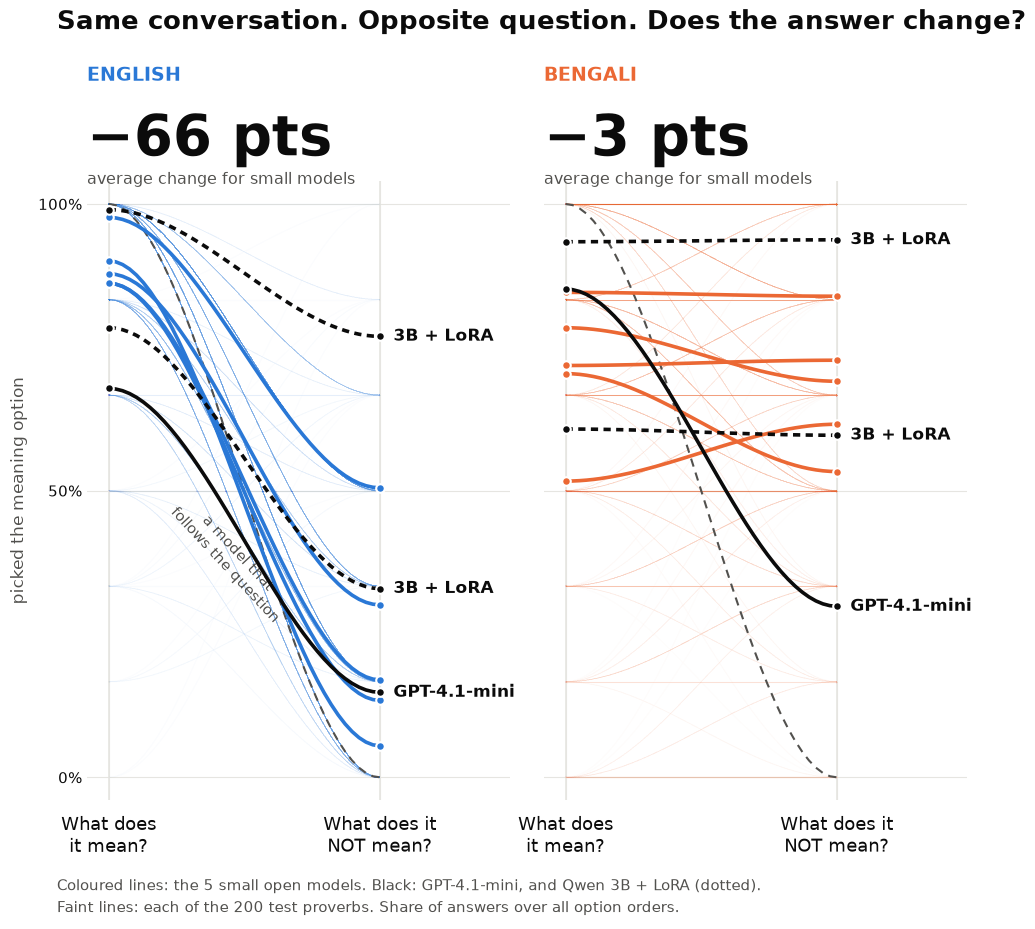

In [44]:
# ================================================================ C0. cover chart: same conversation, opposite question
from matplotlib.collections import LineCollection
COVER_BG = None        # None = transparent PNG (sits on any slide colour), or e.g. "#F3EFE7"
SMALL = [m for m in MODELS if X_RUNS[m][3] not in ("api", "fine-tuned")]           # untuned open models
NAMED = {m: ("GPT-4.1-mini" if X_RUNS[m][3] == "api" else "3B + LoRA")
         for m in MODELS if X_RUNS[m][3] in ("api", "fine-tuned")}

def curve(y0, y1, n=40):
    """smooth S-curve from (0, y0) to (1, y1)"""
    t = np.linspace(0, 1, n)
    return np.c_[t, y0 + (y1 - y0) * t * t * (3 - 2 * t)]

FR = S.pivot(index="model", columns="label", values="fig_rate")                    # model level
PV = (IT[IT["label"].str.match(r"x[12]_(en|bn)$")]                                  # proverb level (3 conversations × orders)
      .groupby(["model_name", "label", "proverb_id"])["fig"].mean().unstack("label"))

fig, axes = plt.subplots(1, 2, figsize=(10, 8.6), sharey=True, facecolor=COVER_BG or "none")
for ax, lang, name in zip(axes, ("en", "bn"), ("ENGLISH", "BENGALI")):
    c, x1, x2 = LANG[lang], f"x1_{lang}", f"x2_{lang}"
    ax.set_facecolor("none")
    for x in (0, 1):
        ax.axvline(x, color=GRID, lw=1.2, zorder=0)
    # faint texture: one curve per model × proverb (small models only)
    sub = PV.loc[PV.index.get_level_values(0).isin(SMALL), [x1, x2]].dropna()
    ax.add_collection(LineCollection([curve(a0, a1) for a0, a1 in sub.values], colors=c, lw=0.9,
                                     alpha=float(np.clip(10 / max(len(sub), 1), 0.015, 0.06)), zorder=1))
    # what a model that follows the question would do
    ax.plot(*curve(1, 0).T, color=MUTED, lw=1.5, ls=(0, (4, 3)), zorder=2)
    # one bold line per model
    for m in MODELS:
        y0, y1 = FR.loc[m, x1], FR.loc[m, x2]
        if np.isnan(y0) or np.isnan(y1):
            continue
        col, ls = (INK, "-" if X_RUNS[m][3] == "api" else (0, (2, 1.5))) if m in NAMED else (c, "-")
        ax.plot(*curve(y0, y1).T, color=col, lw=2.6, ls=ls, solid_capstyle="round", zorder=4)
        ax.scatter([0, 1], [y0, y1], s=38, color=col, edgecolor="white", lw=1.5, zorder=5)
        if m in NAMED:
            ax.text(1.05, y1, NAMED[m], va="center", fontsize=12, color=INK, fontweight="bold")
    # headline number: average drop for the small models
    drop = np.nanmean([(FR.loc[m, x1] - FR.loc[m, x2]) * 100 for m in SMALL])
    ax.text(0, 1.215, name, transform=ax.get_yaxis_transform(), fontsize=14, fontweight="bold", color=c)
    ax.text(0, 1.085, f"{-drop:+.0f} pts".replace("-", "−"), transform=ax.get_yaxis_transform(),
            fontsize=40, fontweight="bold", color=INK)
    ax.text(0, 1.035, "average change for small models", transform=ax.get_yaxis_transform(), fontsize=11.5, color=MUTED)
    ax.set_xlim(-0.08, 1.48); ax.set_ylim(-0.04, 1.04)
    ax.set_xticks([0, 1], ["What does\nit mean?", "What does it\nNOT mean?"], fontsize=13, color=INK)
    ax.tick_params(axis="x", length=0, pad=10)
    ax.spines[:].set_visible(False)

axes[0].set_yticks([0, .5, 1], ["0%", "50%", "100%"], fontsize=11)
for ax in axes:
    ax.tick_params(axis="y", length=0)
axes[0].set_ylabel("picked the meaning option", fontsize=12, color=MUTED, labelpad=8)
axes[0].text(0.5, curve(1, 0)[20, 1] - 0.08, "a model that\nfollows the question", fontsize=10.5, color=MUTED,
             ha="center", va="top", rotation=-47, rotation_mode="anchor")
fig.suptitle("Same conversation. Opposite question. Does the answer change?", x=0.07, y=1.0, ha="left",
             fontsize=19, fontweight="bold", color=INK)
fig.text(0.07, -0.05, f"Coloured lines: the {len(SMALL)} small open models. Black: GPT-4.1-mini, and Qwen 3B + LoRA (dotted).\n"
         f"Faint lines: each of the {PV.index.get_level_values(1).nunique()} test proverbs. Share of answers over all option orders.",
         fontsize=10.5, color=MUTED, linespacing=1.5)
fig.subplots_adjust(left=0.1, right=0.98, top=0.8, bottom=0.08, wspace=0.08)
# fig.text("\nMeaning option = the figurative reading for 170 of the 200 test proverbs, the plain meaning for the other 30.")
for ext in ("png", "svg"):
    fig.savefig(FIG / f"C0_cover_opposite_question.{ext}", dpi=250, bbox_inches="tight", transparent=COVER_BG is None)
plt.show()

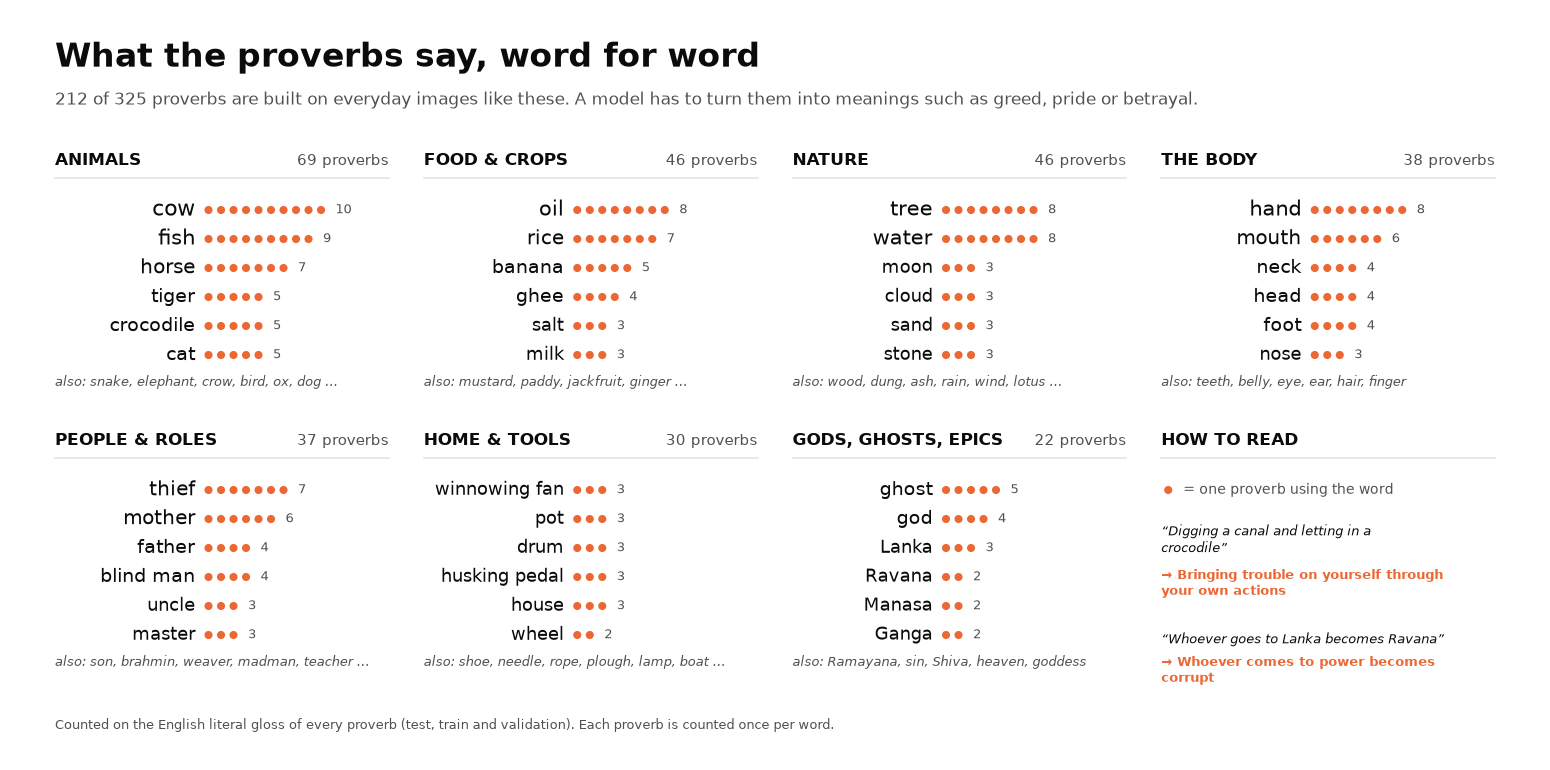

In [42]:
# ---- draw (coordinates in inches)
W, H = 15.3, 7.5
M, GAP = 0.45, 0.35                         # outer margin and space between boxes
CW = (W - 2 * M - 3 * GAP) / 4              # width of one box (wider canvas = wider boxes)
fig = plt.figure(figsize=(W, H), facecolor="none")
ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, W); ax.set_ylim(0, H); ax.axis("off")
DOT, STEP, ROW = LANG["bn"], 0.125, 0.29
nmax = max(n for _, c in summary.values() for n in c.values())

ax.text(M, 7.02, "What the proverbs say, word for word", fontsize=24, fontweight="bold", color=INK, va="center")
ax.text(M, 6.6, f"{any_hit.sum()} of {len(PR)} proverbs are built on everyday images like these. "
        "A model has to turn them into meanings such as greed, pride or betrayal.", fontsize=12.5, color=MUTED, va="center")

def cell(x, y, g):
    total, counts = summary[g]
    ax.text(x, y, g, fontsize=12.5, fontweight="bold", color=INK, va="baseline")
    ax.text(x + CW, y, f"{total} proverbs", fontsize=10.5, color=MUTED, ha="right", va="baseline")
    ax.plot([x, x + CW], [y - 0.13, y - 0.13], color=GRID, lw=1.2)
    words = list(counts.items())
    for i, (w, n) in enumerate(words[:TOP]):
        yy = y - 0.45 - i * ROW
        ax.text(x + 0.42 * CW, yy, w, fontsize=10.5 + 5 * np.sqrt(n / nmax), color=INK, ha="right", va="center")
        ax.scatter(x + 0.46 * CW + np.arange(n) * STEP, np.full(n, yy), s=34, color=DOT, edgecolor="none")
        ax.text(x + 0.46 * CW + n * STEP + 0.02, yy, str(n), fontsize=9, color=MUTED, va="center")
    rest = [w for w, _ in words[TOP:]]
    if rest:
        line = "also: " + ", ".join(rest)
        nmax_c = int(CW * 14)                                     # characters that fit on one line
        line = line if len(line) <= nmax_c else line[:nmax_c - 1].rsplit(",", 1)[0] + " …"
        ax.text(x, y - 0.45 - TOP * ROW + 0.02, line, fontsize=9.5, style="italic", color=MUTED, va="center")

xs = [M + i * (CW + GAP) for i in range(4)]
for i, g in enumerate(order):
    cell(xs[i % 4], 5.95 if i < 4 else 3.15, g)

# last corner: how to read + two decoded examples
x, y = xs[3], 3.15
ax.text(x, y, "HOW TO READ", fontsize=12.5, fontweight="bold", color=INK, va="baseline")
ax.plot([x, x + CW], [y - 0.13, y - 0.13], color=GRID, lw=1.2)
ax.scatter([x + 0.07], [y - 0.45], s=34, color=DOT, edgecolor="none")
ax.text(x + 0.22, y - 0.45, "= one proverb using the word", fontsize=10, color=MUTED, va="center")
yy, FS, WRAP = y - 0.78, 9.5, int(CW * 11.5)
LH = 0.0235 * FS                                  # line height in inches
for key in EXAMPLES:
    m = PR[gloss.str.contains(key.lower(), regex=False)]
    if m.empty:
        continue
    r = m.iloc[0]
    g_txt = textwrap.fill(f"“{r['gloss'].rstrip('.')}”", WRAP)
    m_txt = textwrap.fill(f"→ {r['meaning'].rstrip('.')}", WRAP)
    ax.text(x, yy, g_txt, fontsize=FS, color=INK, va="top", style="italic")
    yy -= LH * (g_txt.count("\n") + 1)
    ax.text(x, yy, m_txt, fontsize=FS, color=DOT, va="top", fontweight="bold")
    yy -= LH * (m_txt.count("\n") + 1) + 0.2

ax.text(M, 0.35, "Counted on the English literal gloss of every proverb (test, train and validation). "
        "Each proverb is counted once per word.", fontsize=9, color=MUTED, va="center")
for ext in ("png", "svg"):
    fig.savefig(FIG / f"D1_proverb_images.{ext}", dpi=250, transparent=True)
plt.show()

In [36]:
# ================================================================ E0. helpers for E1–E4 (run once)
import json, textwrap
from matplotlib.patches import Patch
import matplotlib.patheffects as pe

def short(m):
    return m.replace("Qwen2.5-", "Qwen ")

def picks(label):
    """one row per (model, item): the option with the highest probability after averaging over option orders"""
    d = X[X["label"] == label]
    pc = [c for c in ("p_correct", "p_literal", "p_plausible", "p_none") if c in d and d[c].notna().any()]
    g = d.groupby(["model_name", "item_id", "proverb_id"])
    out = g[pc].mean()
    out["pick"] = out[pc].idxmax(axis=1).str.removeprefix("p_")
    out["gold"] = g["gold_key"].first()
    out["right"] = out["pick"] == out["gold"]
    return out.reset_index()

def load_proverbs(folder=DATASET):
    rows = {}
    for split in ("test", "train", "val"):
        f = Path(folder) / f"{split}.jsonl"
        if f.exists():
            for line in open(f, encoding="utf-8"):
                p = json.loads(line)["proverb"]
                rows[p["proverb_id"]] = {"proverb_id": p["proverb_id"], "rom": p["romanised"].rstrip(". "),
                                         "gloss": p["literal_gloss"].rstrip(".")}
    return pd.DataFrame(rows.values()).set_index("proverb_id") if rows else pd.DataFrame(columns=["rom", "gloss"])

PROV = load_proverbs()
print(len(PROV), "proverbs loaded for labels")

325 proverbs loaded for labels


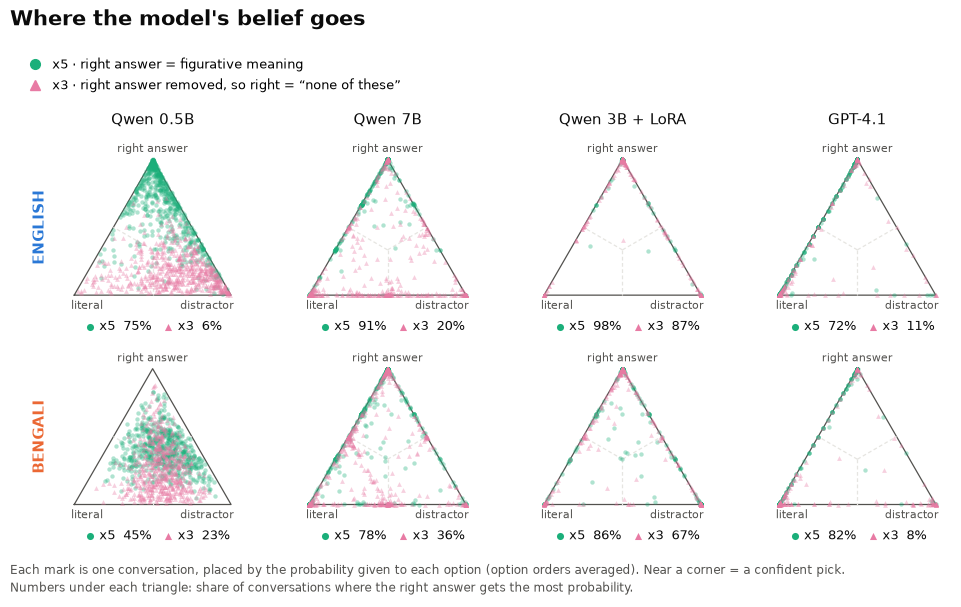

In [41]:
# ================================================================ E1. belief triangles: x5 and x3 together, 4 showcase models
def _pick(kind, largest=True):
    c = [m for m in MODELS if X_RUNS[m][3] == kind and "LoRA" not in m]
    c = sorted(c, key=lambda m: X_RUNS[m][2] or 0)
    return c[-1 if largest else 0] if c else None

SHOW = [m for m in [_pick("instruct", largest=False), _pick("instruct"),
                    next((m for m in MODELS if X_RUNS[m][3] == "fine-tuned"), None), _pick("api")] if m]
# or set by hand: SHOW = ["Qwen2.5-0.5B", "Qwen2.5-7B", "Qwen2.5-3B + LoRA", "GPT-4.1"]

H3 = np.sqrt(3) / 2
TESTS = {   # test: (right-answer key, colour, marker, name)
    "x5": ("correct", "#1baf7a", "o", "x5 · right answer = figurative meaning"),
    "x3": ("none",    "#e87ba4", "^", "x3 · right answer removed, so right = “none of these”"),
}

def tri_xy(p_left, p_right, p_top):
    s = p_left + p_right + p_top
    return (p_right + 0.5 * p_top) / s, H3 * p_top / s

def triangle2(ax, model, lang, corner_labels):
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_xlim(-0.1, 1.1); ax.set_ylim(-0.27, H3 + 0.1)
    ax.fill([0, 1, 0.5], [0, 0, H3], color="white", zorder=0)
    ax.plot([0, 1, 0.5, 0], [0, 0, H3, 0], color=MUTED, lw=0.9, zorder=1)
    for mx, my in [(0.25, H3 / 2), (0.75, H3 / 2), (0.5, 0)]:                 # borders of the three "pick" zones
        ax.plot([0.5, mx], [H3 / 3, my], color=GRID, lw=0.9, ls=(0, (3, 2)), zorder=1)
    for k, (test, (top, col, mk, _)) in enumerate(TESTS.items()):
        keys = [f"p_{top}", "p_literal", "p_plausible"]
        d = X[(X["model_name"] == model) & (X["label"] == f"{test}_{lang}")]
        if d.empty or d[keys].isna().all().any():
            continue
        m = d.groupby("item_id")[keys].mean()                                 # average over option orders
        x, y = tri_xy(m["p_literal"], m["p_plausible"], m[f"p_{top}"])
        ax.scatter(x, y, s=10 if mk == "o" else 12, marker=mk, color=col, alpha=0.35, lw=0, zorder=2 + k)
        share = (m.idxmax(axis=1) == f"p_{top}").mean()
        x0 = 0.1 + 0.5 * k                                                    # both scores on one line
        ax.scatter([x0], [-0.2], s=26, marker=mk, color=col, lw=0, clip_on=False)
        ax.text(x0 + 0.06, -0.2, f"{test}  {share:.0%}", ha="left", va="center", fontsize=9.5, color=INK)
    if corner_labels:
        ax.text(0.5, H3 + 0.03, "right answer", ha="center", va="bottom", fontsize=8, color=MUTED)
        ax.text(-0.02, -0.03, "literal", ha="left", va="top", fontsize=8, color=MUTED)
        ax.text(1.02, -0.03, "distractor", ha="right", va="top", fontsize=8, color=MUTED)

fig, axes = plt.subplots(2, len(SHOW), figsize=(2.35 * len(SHOW) + 0.5, 5.6), squeeze=False)
for j, m in enumerate(SHOW):
    for i, lang in enumerate(("en", "bn")):
        triangle2(axes[i, j], m, lang, corner_labels=True)
    axes[0, j].set_title(short(m), fontsize=11, color=INK, pad=14)
for i, (lang, nm) in enumerate([("en", "ENGLISH"), ("bn", "BENGALI")]):
    axes[i, 0].text(-0.22, H3 / 2, nm, rotation=90, ha="center", va="center", fontsize=10.5, fontweight="bold",
                    color=LANG[lang])
from matplotlib.lines import Line2D
fig.legend([Line2D([], [], marker=v[2], ls="", color=v[1], ms=7) for v in TESTS.values()],
           [v[3] for v in TESTS.values()], loc="upper left", bbox_to_anchor=(0.02, 0.915), ncol=1, frameon=False,
           fontsize=9.5, handletextpad=0.3)
fig.suptitle("Where the model's belief goes", x=0.02, ha="left", fontsize=15, fontweight="bold", color=INK)
fig.text(0.02, -0.06, "Each mark is one conversation, placed by the probability given to each option (option orders "
         "averaged). Near a corner = a confident pick.\n"
         "Numbers under each triangle: share of conversations where the right answer gets the most probability.",
         fontsize=8.5, color=MUTED, linespacing=1.5)
fig.subplots_adjust(left=0.05, right=0.99, top=0.74, bottom=0.02, wspace=0.04, hspace=0.08)
fig.savefig(FIG / "E1_belief_triangles.png", dpi=220, bbox_inches="tight", transparent=True); plt.show()

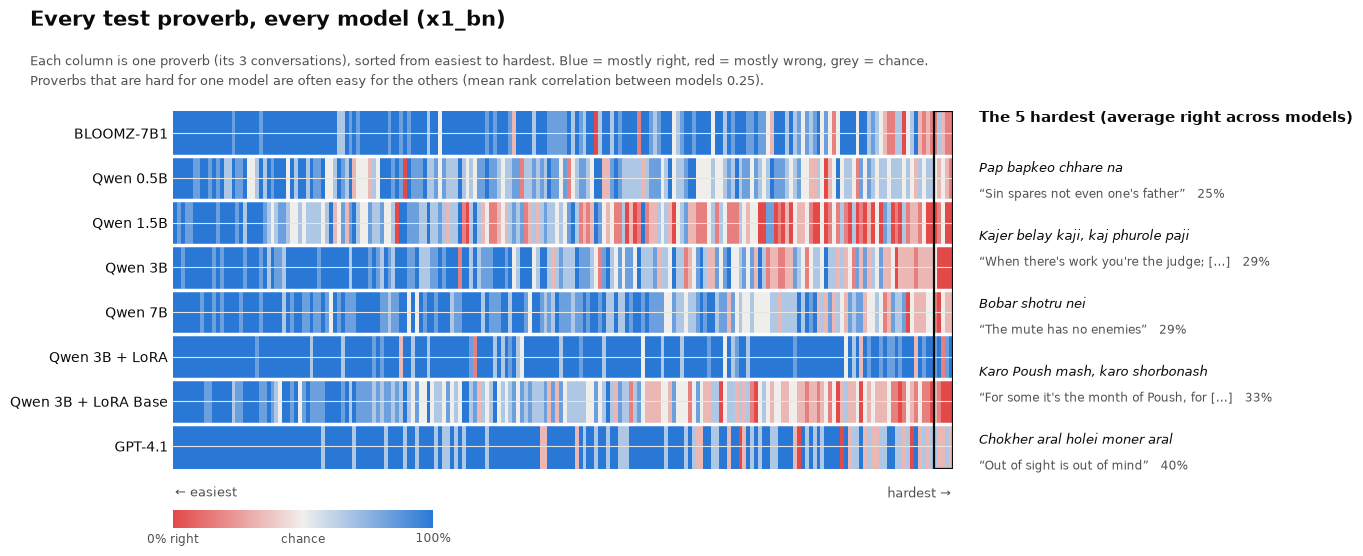

In [38]:
# ================================================================ E2. proverb difficulty barcode
BAR_LABEL = "x1_bn"        # any condition, e.g. "x5_bn", "x2_bn", "x1_en"
N_HARD = 5

A = IT[IT["label"] == BAR_LABEL].groupby(["model_name", "proverb_id"])["acc"].mean().unstack()
A = A.reindex([m for m in MODELS if m in A.index])
cols = A.mean().sort_values(ascending=False).index                  # easiest → hardest (mean over models)
A = A[cols]
rho = A.T.corr(method="spearman").values
r = rho[np.triu_indices_from(rho, 1)].mean()
ch = chance(BAR_LABEL)
n_all_fail = int((A < ch).all().sum())

fig = plt.figure(figsize=(13, 0.42 * len(A) + 2.6))
ax = fig.add_axes([0.13, 0.2, 0.6, 0.6])
ax.imshow(A.values, aspect="auto", cmap=DIV, norm=TwoSlopeNorm(vcenter=ch, vmin=0, vmax=1), interpolation="nearest")
for i in range(len(A) - 1):
    ax.axhline(i + 0.5, color="white", lw=2.5)
ax.set_yticks(range(len(A)), [short(m) for m in A.index], fontsize=10)
ax.set_xticks([]); ax.tick_params(length=0); ax.spines[:].set_visible(False)
ax.text(0, len(A) - 0.1, "← easiest", fontsize=9.5, color=MUTED, va="top")
ax.text(A.shape[1] - 1, len(A) - 0.1, "hardest →", fontsize=9.5, color=MUTED, va="top", ha="right")
ax.add_patch(plt.Rectangle((A.shape[1] - N_HARD - 0.5, -0.5), N_HARD, len(A), fill=False, ec=INK, lw=1.6, zorder=3))

# list of the hardest proverbs on the right
hard = list(cols[-N_HARD:][::-1])
side = fig.add_axes([0.75, 0.2, 0.24, 0.6]); side.axis("off"); side.set_xlim(0, 1); side.set_ylim(0, 1)
side.text(0, 1.0, f"The {N_HARD} hardest (average right across models)", fontsize=10.5, fontweight="bold", color=INK, va="top")
for k, pid in enumerate(hard):
    name = PROV.loc[pid, "rom"] if pid in PROV.index else pid
    gl = PROV.loc[pid, "gloss"] if pid in PROV.index else ""
    yy = 0.86 - k * 0.19
    side.text(0, yy, textwrap.shorten(name, 38), fontsize=9.5, color=INK, va="top", style="italic")
    side.text(0, yy - 0.075, textwrap.shorten(f"“{gl}”", 46) + f"   {A[pid].mean():.0%}", fontsize=8.5,
              color=MUTED, va="top")

agree = "tend to be hard for the others" if r >= 0.3 else "are often easy for the others"
fig.text(0.02, 0.97, f"Every test proverb, every model ({BAR_LABEL})", fontsize=15, fontweight="bold", color=INK, va="top")
fig.text(0.02, 0.9, "Each column is one proverb (its 3 conversations), sorted from easiest to hardest. "
         "Blue = mostly right, red = mostly wrong, grey = chance.\n"
         f"Proverbs that are hard for one model {agree} (mean rank correlation between models {r:.2f})"
         + (f"; {n_all_fail} are below chance for every model." if n_all_fail else "."),
         fontsize=9.5, color=MUTED, va="top", linespacing=1.5)
cax = fig.add_axes([0.13, 0.1, 0.2, 0.03])
cb = fig.colorbar(ax.images[0], cax=cax, orientation="horizontal", ticks=[0, ch, 1])
cb.ax.set_xticklabels(["0% right", "chance", "100%"], fontsize=8.5); cb.outline.set_visible(False)
cb.ax.tick_params(length=0, colors=MUTED)
fig.savefig(FIG / f"E2_difficulty_barcode_{BAR_LABEL}.png", dpi=220, bbox_inches="tight", transparent=True); plt.show()

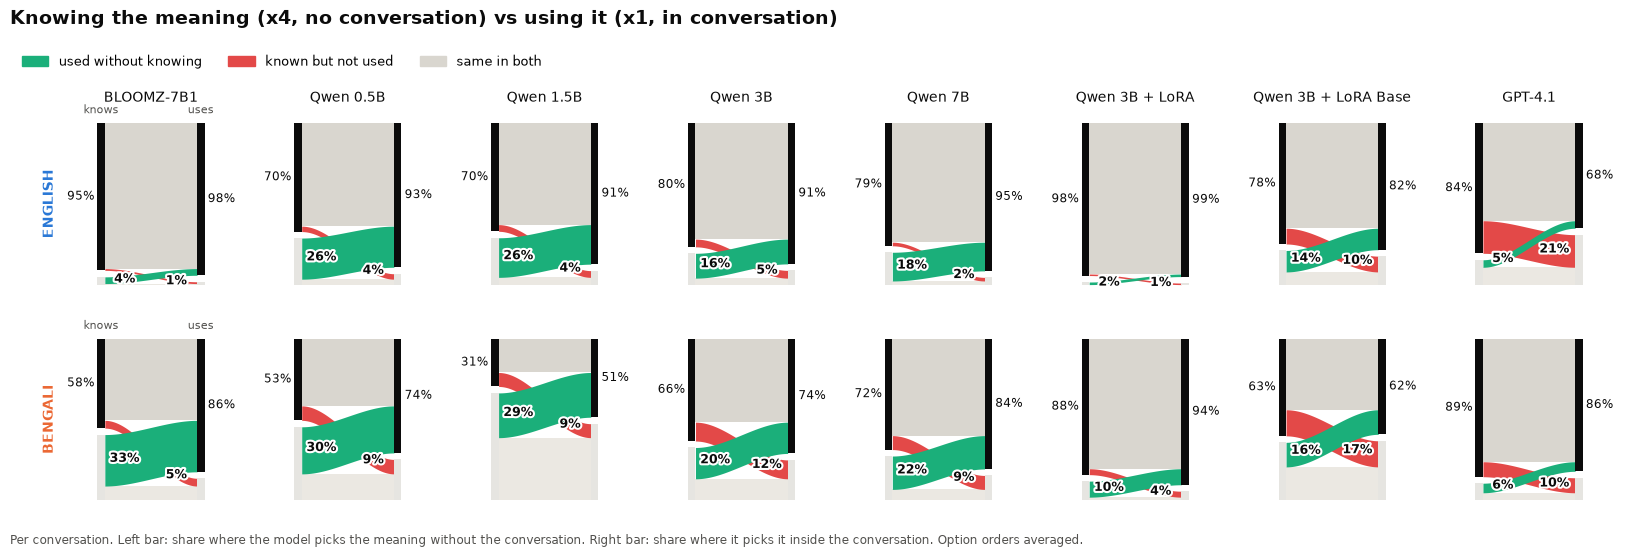

In [39]:
# ================================================================ E3. knowing → using, per conversation
FLOW_MODELS = MODELS
FLOW_COL = {"KK": "#d9d6cf", "NN": "#ebe8e2", "NK": "#1baf7a", "KN": LOSS}
FLOW_NAME = {"NK": "used without knowing", "KN": "known but not used"}

def ribbon(ax, x0, x1, a0, b0, a1, b1, color, n=50):
    """band from [a0, b0] at x0 to [a1, b1] at x1 (bottom, top), S-shaped"""
    t = np.linspace(0, 1, n); s = t * t * (3 - 2 * t)
    ax.fill_between(x0 + (x1 - x0) * t, a0 + (a1 - a0) * s, b0 + (b1 - b0) * s, color=color, lw=0, zorder=1)

def know_use(ax, model, lang, labels):
    k = picks(f"x4_{lang}"); u = picks(f"x1_{lang}")
    k, u = k[k["model_name"] == model], u[u["model_name"] == model]
    j = k.merge(u, on=["model_name", "item_id"], suffixes=("_k", "_u"))
    ax.axis("off"); ax.set_xlim(-0.35, 1.35); ax.set_ylim(-0.08, 1.08)
    if j.empty:
        ax.text(0.5, 0.5, "no data", ha="center", fontsize=8, color=MUTED); return None
    n = len(j)
    c = {"KK": (j.right_k & j.right_u).sum() / n, "KN": (j.right_k & ~j.right_u).sum() / n,
         "NK": (~j.right_k & j.right_u).sum() / n, "NN": (~j.right_k & ~j.right_u).sum() / n}
    gap, w = 0.04, 0.07
    sc = 1 - gap
    # left stack (top→bottom): KK, KN | gap | NK, NN ; right stack: KK, NK | gap | KN, NN
    L = {}; y = 1.0
    for key in ("KK", "KN"):
        L[key] = (y - c[key] * sc, y); y -= c[key] * sc
    y -= gap
    for key in ("NK", "NN"):
        L[key] = (y - c[key] * sc, y); y -= c[key] * sc
    R = {}; y = 1.0
    for key in ("KK", "NK"):
        R[key] = (y - c[key] * sc, y); y -= c[key] * sc
    y -= gap
    for key in ("KN", "NN"):
        R[key] = (y - c[key] * sc, y); y -= c[key] * sc
    for key in ("KK", "NN", "KN", "NK"):
        ribbon(ax, w, 1 - w, L[key][0], L[key][1], R[key][0], R[key][1], FLOW_COL[key])
    know_top, use_top = L["KN"][0], R["NK"][0]
    ax.fill_between([0, w], know_top, 1, color=INK, lw=0); ax.fill_between([0, w], 0, L["NK"][1], color=GRID, lw=0)
    ax.fill_between([1 - w, 1], use_top, 1, color=INK, lw=0); ax.fill_between([1 - w, 1], 0, R["KN"][1], color=GRID, lw=0)
    for key, t in (("NK", 0.22), ("KN", 0.78)):                        # label each cross-flow away from the crossing
        if c[key] >= 0.01:
            s_ = t * t * (3 - 2 * t)
            y0, y1 = (L[key][0] + L[key][1]) / 2, (R[key][0] + R[key][1]) / 2
            ax.text(w + (1 - 2 * w) * t, y0 + (y1 - y0) * s_, f"{c[key]:.0%}", ha="center", va="center", fontsize=9,
                    fontweight="bold", color=INK, zorder=3, path_effects=[pe.withStroke(linewidth=3, foreground="white")])
    ax.text(-0.03, (know_top + 1) / 2, f"{c['KK'] + c['KN']:.0%}", ha="right", va="center", fontsize=8.5, color=INK)
    ax.text(1.03, (use_top + 1) / 2, f"{c['KK'] + c['NK']:.0%}", ha="left", va="center", fontsize=8.5, color=INK)
    if labels:
        ax.text(w / 2, 1.06, "knows", ha="center", fontsize=8, color=MUTED)
        ax.text(1 - w / 2, 1.06, "uses", ha="center", fontsize=8, color=MUTED)
    return c

fig, axes = plt.subplots(2, len(FLOW_MODELS), figsize=(2.0 * len(FLOW_MODELS) + 0.6, 5.6), squeeze=False)
for jx, m in enumerate(FLOW_MODELS):
    for i, lang in enumerate(("en", "bn")):
        know_use(axes[i, jx], m, lang, labels=(jx == 0))
    axes[0, jx].set_title(short(m), fontsize=10, color=INK, pad=6)
for i, (lang, nm) in enumerate([("en", "ENGLISH"), ("bn", "BENGALI")]):
    axes[i, 0].text(-0.45, 0.5, nm, rotation=90, ha="center", va="center", fontsize=10, fontweight="bold", color=LANG[lang])
fig.legend([Patch(color=FLOW_COL["NK"]), Patch(color=FLOW_COL["KN"]), Patch(color=FLOW_COL["KK"])],
           [FLOW_NAME["NK"], FLOW_NAME["KN"], "same in both"], loc="upper left", bbox_to_anchor=(0.02, 0.92),
           ncol=3, frameon=False, fontsize=9.5)
fig.suptitle("Knowing the meaning (x4, no conversation) vs using it (x1, in conversation)", x=0.02, ha="left",
             fontsize=14, fontweight="bold", color=INK)
fig.text(0.02, 0.025, "Per conversation. Left bar: share where the model picks the meaning without the conversation. "
         "Right bar: share where it picks it inside the conversation. Option orders averaged.", fontsize=8.5, color=MUTED)
fig.subplots_adjust(left=0.05, right=0.99, top=0.8, bottom=0.08, wspace=0.08, hspace=0.15)
fig.savefig(FIG / "E3_knowing_to_using.png", dpi=220, bbox_inches="tight", transparent=True); plt.show()

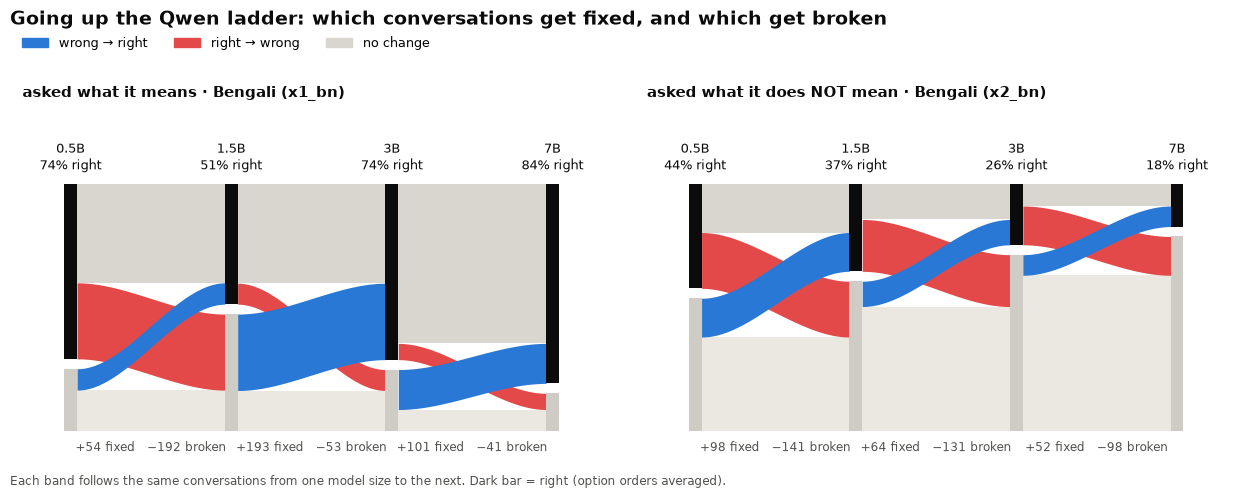

In [40]:
# ================================================================ E4. scale churn along the Qwen ladder
CHURN_LABELS = ["x1_bn", "x2_bn"]
LADDER_M = sorted([m for m in MODELS if X_RUNS[m][1] == "Qwen2.5" and X_RUNS[m][3] == "instruct" and "LoRA" not in m],
                  key=lambda m: X_RUNS[m][2])
CH_COL = {"RR": "#d9d6cf", "WW": "#ebe8e2", "WR": GAIN, "RW": LOSS}

def churn(ax, label):
    p = picks(label)
    M = p[p["model_name"].isin(LADDER_M)].pivot(index="item_id", columns="model_name", values="right")[LADDER_M].dropna()
    ax.axis("off"); ax.set_xlim(-0.3, len(LADDER_M) - 0.7); ax.set_ylim(-0.12, 1.16)
    n, gap, w = len(M), 0.04, 0.08
    sc = 1 - gap
    for i in range(len(LADDER_M) - 1):
        a, b = M.iloc[:, i].astype(bool), M.iloc[:, i + 1].astype(bool)
        c = {"RR": (a & b).mean(), "RW": (a & ~b).mean(), "WR": (~a & b).mean(), "WW": (~a & ~b).mean()}
        L, y = {}, 1.0
        for key in ("RR", "RW"):
            L[key] = (y - c[key] * sc, y); y -= c[key] * sc
        y -= gap
        for key in ("WR", "WW"):
            L[key] = (y - c[key] * sc, y); y -= c[key] * sc
        R, y = {}, 1.0
        for key in ("RR", "WR"):
            R[key] = (y - c[key] * sc, y); y -= c[key] * sc
        y -= gap
        for key in ("RW", "WW"):
            R[key] = (y - c[key] * sc, y); y -= c[key] * sc
        for key in ("RR", "WW", "RW", "WR"):
            ribbon(ax, i + w / 2, i + 1 - w / 2, L[key][0], L[key][1], R[key][0], R[key][1], CH_COL[key])
        ax.text(i + 0.5, -0.08, f"+{c['WR'] * n:.0f} fixed   −{c['RW'] * n:.0f} broken", ha="center",
                fontsize=8.5, color=MUTED)
    for i, m in enumerate(LADDER_M):
        r = M[m].mean()
        top = 1 - r * sc
        ax.fill_between([i - w / 2, i + w / 2], top, 1, color=INK, lw=0, zorder=2)
        ax.fill_between([i - w / 2, i + w / 2], 0, top - gap, color="#cfccc5", lw=0, zorder=2)
        ax.text(i, 1.04, f"{short(m).replace('Qwen ', '')}\n{r:.0%} right", ha="center", va="bottom", fontsize=9.5,
                color=INK, linespacing=1.3)
    ax.set_title({"x1": "asked what it means", "x2": "asked what it does NOT mean"}.get(label[:2], label) +
                 f" · {'Bengali' if label.endswith('bn') else 'English'} ({label})", loc="left", fontsize=10.5,
                 color=INK, fontweight="bold", pad=34)

if len(LADDER_M) >= 2:
    fig, axes = plt.subplots(1, len(CHURN_LABELS), figsize=(6.2 * len(CHURN_LABELS), 4.8), squeeze=False)
    for ax, lab in zip(axes[0], CHURN_LABELS):
        churn(ax, lab)
    fig.legend([Patch(color=CH_COL["WR"]), Patch(color=CH_COL["RW"]), Patch(color=CH_COL["RR"])],
               ["wrong → right", "right → wrong", "no change"], loc="upper left", bbox_to_anchor=(0.01, 0.95),
               ncol=3, frameon=False, fontsize=9.5)
    fig.suptitle("Going up the Qwen ladder: which conversations get fixed, and which get broken", x=0.01, ha="left",
                 fontsize=14, fontweight="bold", color=INK)
    fig.text(0.01, -0.01, "Each band follows the same conversations from one model size to the next. "
             "Dark bar = right (option orders averaged).", fontsize=8.5, color=MUTED)
    fig.subplots_adjust(left=0.02, right=0.99, top=0.7, bottom=0.04, wspace=0.08)
    fig.savefig(FIG / "E4_scale_churn.png", dpi=220, bbox_inches="tight", transparent=True); plt.show()